# 02 · EDA: exclusión de distribuidores, perfiles de cliente y variables para el sistema de recomendación

**Objetivos**
1. Entender el dataset (diccionario, univariado, bivariado y multivariado).
2. **Detectar y excluir a los distribuidores**: no sirven para entrenar el recomendador. El resto del EDA se hace sin ellos.
3. Segmentar al resto en **3 perfiles de cliente** según su recurrencia (`perfil_cliente`).
4. Construir las variables derivadas para el recomendador.

**Convenciones:** `df0` / `v0` es el dataset completo (solo se usa en la sección 2); `df` / `v` es el dataset sin distribuidores. `v` son las compras válidas (`es_compra_valida`), que es lo que el modelo aprende. Montos en PKR; el ticket se mide por pedido (`grand_total` una vez por `increment_id`).



In [ ]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import CategoricalDtype
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold", "axes.titlesize": 11})

COL_SEG = {"Individual": "#2a9d8f", "Zona gris": "#e9c46a", "Distribuidor probable": "#e63946"}
ORDEN_PERFIL = ["Bajo perfil", "Perfil intermedio", "Alto perfil"]
COL_PERFIL = dict(zip(ORDEN_PERFIL, ["#b0b0b0", "#e9c46a", "#2a9d8f"]))
AZUL = "#264653"

In [2]:
# Funciones auxiliares (gráficos y tablas)
def hist_log(ax, s, titulo, mediana=True):
    """Histograma de log10 de los valores positivos, con línea en la mediana."""
    x = s[s > 0]
    ax.hist(np.log10(x), bins=60, color=AZUL); ax.set_title(titulo)
    if mediana:
        ax.axvline(np.log10(x.median()), color="#e63946", ls="--", label=f"mediana = {x.median():,.0f}"); ax.legend()

def barras_cap(ax, s, cap, titulo, pct=False, log=False):
    """Barras de frecuencia con los valores >= cap agrupados en 'cap+'."""
    c = s.clip(upper=cap).value_counts().sort_index()
    etq = [str(i) for i in c.index]; etq[-1] += "+"
    ax.bar(etq, c.values / len(s) * 100 if pct else c.values, color=AZUL); ax.set_title(titulo)
    if log: ax.set_yscale("log")

def pca_scatter(ax, X, grupos, colores, n, titulo):
    """Dispersión de las 2 primeras componentes (muestra de n clientes) coloreada por grupo."""
    Z = PCA(2, random_state=SEED).fit_transform(X); idx = rng.choice(len(X), n, replace=False)
    g = np.asarray(grupos)[idx]
    for nombre, color in colores.items():
        ax.scatter(Z[idx][g == nombre, 0], Z[idx][g == nombre, 1], s=4, alpha=0.35, color=color, label=nombre)
    ax.set(title=titulo, xlabel="PC1", ylabel="PC2"); ax.legend(markerscale=4)



def agregar_friccion(cli, df, v):
    """Agrega a la tabla de clientes canal, pago y fricción (cancelaciones y reembolsos usan todas las transacciones)."""
    tasa = pd.crosstab(df.customer_id, df.grupo_status)
    cli["tasa_cancelacion"] = (tasa.cancelada / tasa.sum(axis=1)).reindex(cli.index) * 100
    cli["tasa_reembolso"] = (tasa.reembolso / tasa.sum(axis=1)).reindex(cli.index) * 100
    cli["pct_cod"] = v.assign(c=v.payment_method == "cod").groupby("customer_id").c.mean() * 100
    cli["pct_codigo_comision"] = v.groupby("customer_id").uso_codigo_comision.mean() * 100
    cli["cuenta_interna"] = v.groupby("customer_id").cuenta_interna_probable.max()
    return cli

def lift(sub):
    """Lift de co-compra entre categorías a nivel cliente: P(A∩B) / (P(A)·P(B))."""
    B = (pd.crosstab(sub.customer_id, sub.category_name_1) > 0).astype(int).drop(columns="Desconocida", errors="ignore")
    co = (B.T @ B) / len(B); p = B.mean()
    return (co / np.outer(p, p)).mask(np.eye(len(co), dtype=bool))

FEATS_PCA = ["n_pedidos", "gasto_bruto", "ticket_mediano", "unidades_por_pedido", "max_unidades_pedido", "skus_distintos", "n_categorias", "meses_activos"]
FEATS_ACT = ["n_pedidos", "skus_distintos", "n_categorias", "unidades_por_pedido", "max_unidades_pedido", "gasto_bruto"]   # actividad, sin ticket

In [ ]:
df0 = pd.read_parquet(transacciones_limpias.parquet).astype({"item_id": "int64", "customer_id": "int64", "qty_ordered": "int64", "cuenta_interna_probable": "bool"})

# df0 / v0 = dataset completo (antes de excluir distribuidores)
GRUPO = {"complete": "válida", "received": "válida", "closed": "válida", "paid": "válida", "cod": "válida",
         "exchange": "válida", "canceled": "cancelada", "order_refunded": "reembolso", "refund": "reembolso"}
df0["grupo_status"] = df0.status.map(GRUPO).fillna("otro")
VALIDOS = sorted(df0.loc[df0.es_compra_valida, "status"].unique())
v0 = df0[df0.es_compra_valida].copy()

display(pd.DataFrame({"líneas": [len(df0), len(v0)], "pedidos": [df0.increment_id.nunique(), v0.increment_id.nunique()],
                      "clientes": [df0.customer_id.nunique(), v0.customer_id.nunique()]}, index=["todas las transacciones", "compras válidas"]))
print(f"{RUTA.name} · período {df0.created_at.min():%Y-%m-%d} → {df0.created_at.max():%Y-%m-%d}")

NameError: name 'transacciones_limpias' is not defined

## 1. Diccionario de variables

| Variable | Descripción |
|---|---|
| `item_id` | Identificador único de la línea de pedido (un producto dentro de un pedido). |
| `increment_id` | Identificador del pedido. Un pedido puede tener varias líneas. |
| `customer_id` | Identificador del cliente. |
| `customer_since` | Mes de alta del cliente. |
| `created_at` | Fecha de la transacción. |
| `anio_mes` | Período AAAA-MM derivado de `created_at`. |
| `status` | Estado de la transacción (complete, canceled, received, order_refunded...). |
| `es_compra_valida` | True si el estado es complete, received, closed, paid, cod o exchange. |
| `sku` | Código del producto. |
| `category_name_1` | Categoría del producto ("Desconocida" si no se pudo imputar). |
| `price` | Precio unitario en PKR (rupias paquistaníes). |
| `qty_ordered` | Unidades de la línea. |
| `discount_amount` | Descuento de la línea en PKR. |
| `monto_bruto` | `price × qty_ordered`, en PKR. |
| `monto_linea` | Monto neto de la línea: `max(price × qty − descuento, 0)`. |
| `grand_total` | Total del pedido, repetido en cada línea. |
| `payment_method` | Método de pago (`cod` = contra entrega). |
| `uso_codigo_comision` | True si la línea tenía código de comisión de ventas (vendedor/afiliado). |
| `precio_cero` | `price = 0`. |
| `descuento_inconsistente` | El descuento de la línea supera `price × qty`. |
| `grand_total_negativo` | `grand_total < 0`. |
| `qty_atipica` | `qty_ordered > 100`. |
| `cuenta_interna_probable` | ≥30 % de las compras del cliente eran de productos de prueba. |

## 2. Estadísticas básicas


In [ ]:
df0.describe()

## 2. Detección y exclusión de distribuidores



**Por qué se excluyen, y antes de analizar.** El recomendador debe lograr que un cliente intermedio descubra productos y se vuelva recurrente. Un distribuidor no es ese cliente:
1. **Compra para revender:** su demanda es reposición, no preferencia (mediana de 26 SKUs y 7 categorías).
2. **Distorsiona:** son muy pocos pero aportan una parte enorme de las líneas, e **inflan la co-compra** entre categorías (se cuantifica abajo).
3. **No es el usuario objetivo:** no hay que "convertirlo" en alto perfil, porque ya lo es en volumen.

Se excluyen con todo su historial y la lista queda en `distribuidores_excluidos.parquet`, por si más adelante se quiere una lógica de reposición propia.

**Método.** Un distribuidor no se define por un ticket alto (quien compra un celular también lo tiene) sino por una *combinación*: compra seguido, variado, en cantidad y/o con gasto acumulado muy alto.
1. Cinco señales binarias (top 3 %, percentil 97): frecuencia, variedad de SKUs, gasto total, unidades en un pedido y variedad de categorías.
2. 0-1 señales = *Individual*; 2 = *Zona gris*; 3 o más = *Distribuidor probable*. Regla dura: un pedido de 50 unidades o más → *Distribuidor probable*.
3. Validación con clustering y con variables que la regla no usó.
4. **Solo se excluye al *Distribuidor probable***; la zona gris se mantiene.

Primero, quiénes son los que más gastan:

In [ ]:
def armar_ped(v):
    """Tabla de pedidos a partir de líneas válidas. Condensa la información de cada pedido"""
    return (v.groupby("increment_id")
              .agg(customer_id=("customer_id", "first"), fecha=("created_at", "min"), lineas=("item_id", "size"),
                   unidades=("qty_ordered", "sum"), skus=("sku", "nunique"), cats=("category_name_1", "nunique"),
                   bruto=("monto_bruto", "sum"), grand_total=("grand_total", "first")).reset_index())

def armar_cli(v, ped):
    """Tabla de clientes (solo con compra válida): frecuencia, gasto, variedad y actividad."""
    g, gv = ped.groupby("customer_id"), v.groupby("customer_id")
    cli = pd.DataFrame({
        "n_pedidos": g.size(), "n_lineas": gv.size(), "unidades": g.unidades.sum(), "gasto_bruto": g.bruto.sum(),
        "ticket_mediano": g.grand_total.median().clip(lower=0), "unidades_por_pedido": g.unidades.mean(),
        "max_unidades_pedido": g.unidades.max(), "lineas_por_pedido": g.lineas.mean(),
        "skus_distintos": gv.sku.nunique(), "n_categorias": gv.category_name_1.nunique(),
        "meses_activos": gv.anio_mes.nunique(), "primera_compra": gv.created_at.min(), "ultima_compra": gv.created_at.max()})
    cli["pedidos_por_mes_activo"] = cli.n_pedidos / cli.meses_activos
    return cli

In [ ]:
ped0 = armar_ped(v0)
cli0 = armar_cli(v0, ped0)
print(f"Clientes con compra válida (dataset completo): {len(cli0):,}")
cli0.nlargest(12, "gasto_bruto")[["n_pedidos", "unidades", "gasto_bruto", "unidades_por_pedido", "max_unidades_pedido", "skus_distintos", "n_categorias", "meses_activos"]].round(1)

Clientes con compra válida (dataset completo): 79,946


,n_pedidos,unidades,gasto_bruto,unidades_por_pedido,max_unidades_pedido,skus_distintos,n_categorias,meses_activos
customer_id,,,,,,,,
50387,1,2000,17888000.0,2000.0,2000,2,1,1
44619,159,183,3487818.0,1.2,5,66,2,9
109038,23,47,3386254.0,2.0,4,27,6,3
33,823,1219,3043654.8,1.5,22,504,15,23
36,689,810,2633844.7,1.2,10,494,16,11
114,601,795,2587236.0,1.3,13,186,13,18
800,495,602,2515702.0,1.2,7,405,13,25
110215,14,27,2508684.0,1.9,4,13,1,2
459,216,240,2442559.0,1.1,5,86,10,15


**Lectura:** hay dos arquetipos. (a) *Distribuidores recurrentes*: cientos de pedidos y SKUs, 13-16 categorías y 11-25 meses activos (clientes 33, 36, 114, 800...). (b) *Volumen extremo*, como el cliente 50387 (un pedido de 2.000 unidades por PKR 17,9 M). También hay gasto altísimo con poca variedad (44619: 159 pedidos y 2 categorías; 110215: 14 pedidos y 1 categoría), a revisar. El gasto solo no define el tipo de cliente.

In [ ]:
SENALES = {"frecuencia": "n_pedidos", "variedad de SKUs": "skus_distintos", "gasto total": "gasto_bruto",
           "unidades en un pedido": "max_unidades_pedido", "variedad de categorías": "n_categorias"}
umbral = {s: cli0[c].quantile(0.97) for s, c in SENALES.items()}          # percentil 97 de cada variable
for s, c in SENALES.items():
    cli0[f"s_{s}"] = cli0[c] >= umbral[s]
cols_s = [f"s_{s}" for s in SENALES]
cli0["n_senales"] = cli0[cols_s].sum(axis=1)

display(pd.DataFrame({"variable": list(SENALES.values()), "umbral (≥)": list(umbral.values()),
                      "% clientes que la cumple": [cli0[c].mean() * 100 for c in cols_s]}, index=list(SENALES)).round(1))
print("Clientes con algún pedido de ≥ N unidades:", {u: int((cli0.max_unidades_pedido >= u).sum()) for u in (20, 30, 50, 100)})
print("Clientes según nº de señales:", cli0.n_senales.value_counts().sort_index().to_dict())
cli0[cols_s].corr().round(2)

,variable,umbral (≥),% clientes que la cumple
frecuencia,n_pedidos,10.0,3.0
variedad de SKUs,skus_distintos,15.0,3.0
gasto total,gasto_bruto,106658.2,3.0
unidades en un pedido,max_unidades_pedido,8.0,3.0
variedad de categorías,n_categorias,5.0,4.2


Clientes con algún pedido de ≥ N unidades: {20: 341, 30: 123, 50: 40, 100: 12}
Clientes según nº de señales: {0: 72931, 1: 3876, 2: 1331, 3: 1010, 4: 612, 5: 186}


,s_frecuencia,s_variedad de SKUs,s_gasto total,s_unidades en un pedido,s_variedad de categorías
s_frecuencia,1.00,0.64,0.37,0.27,0.52
s_variedad de SKUs,0.64,1.00,0.18,0.47,0.62
s_gasto total,0.37,0.18,1.00,0.08,0.13
s_unidades en un pedido,0.27,0.47,0.08,1.00,0.33
s_variedad de categorías,0.52,0.62,0.13,0.33,1.00


**Lectura:** cada señal marca cerca del 3 % de los clientes (4,2 % en categorías, por empates). Umbrales: 10 pedidos, 15 SKUs, PKR 106.658, 8 unidades en un pedido y 5 categorías. Las señales se correlacionan (frecuencia y SKUs: 0,64) pero **el gasto es la más independiente** (0,08-0,37), lo que justifica exigir varias a la vez. Hay 3.139 clientes con 2 o más señales (3,9 %) y 1.808 con 3 o más; 40 compraron 50 unidades o más en un pedido y 12, 100 o más.

In [ ]:
UMBRAL_GRANEL = 50            # unidades en un solo pedido: nadie compra esto para consumo propio
cli0["segmento"] = np.select([cli0.n_senales >= 3, cli0.n_senales == 2], ["Distribuidor probable", "Zona gris"], default="Individual")
cli0.loc[cli0.max_unidades_pedido >= UMBRAL_GRANEL, "segmento"] = "Distribuidor probable"
es_dist = cli0.segmento == "Distribuidor probable"
cli0["tipo_distribuidor"] = np.where(~es_dist, "—", np.where(cli0.s_frecuencia, "Distribuidor recurrente", "Comprador de granel"))

res = cli0.groupby("segmento").agg(clientes=("gasto_bruto", "size"), gasto=("gasto_bruto", "sum"), pedidos=("n_pedidos", "sum"))
for col in ("clientes", "pedidos", "gasto"):
    res[f"% {col}"] = res[col] / res[col].sum() * 100
display(res[["clientes", "% clientes", "% pedidos", "% gasto"]].round(1).loc[list(COL_SEG)])
print(cli0[es_dist].tipo_distribuidor.value_counts().to_string())

,clientes,% clientes,% pedidos,% gasto
segmento,,,,
Individual,76799,96.1,64.9,66.1
Zona gris,1323,1.7,6.4,11.2
Distribuidor probable,1824,2.3,28.6,22.7


tipo_distribuidor
Distribuidor recurrente    1525
Comprador de granel         299


**Lectura:** **1.824 clientes (2,3 %) son distribuidores probables y generan el 28,6 % de los pedidos y el 22,7 % del gasto**: 1.525 *recurrentes* (cumplen la señal de frecuencia) y 299 *de granel*. Otros 1.323 (1,7 %) quedan en zona gris y el 96,1 % son individuos.

**La zona gris se mantiene:** es una banda ambigua (medianas de 10 pedidos, 13 SKUs y 4 categorías) y excluirla sería más agresivo de lo que la evidencia respalda. Queda marcada con `zona_gris` para probar su efecto.

In [ ]:
# Validación 1: clustering no supervisado sobre variables de actividad (sin ticket)
Xa = StandardScaler().fit_transform(np.log1p(cli0[FEATS_ACT]))
sil = {k: silhouette_score(Xa, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xa), sample_size=20000, random_state=SEED) for k in range(2, 8)}
print("Silhouette por k:", {k: round(s, 3) for k, s in sil.items()})

cli0["cluster"] = KMeans(5, n_init=10, random_state=SEED).fit_predict(Xa)
perfil = cli0.groupby("cluster")[FEATS_ACT].median().round(1)
perfil["clientes"] = cli0.cluster.value_counts()
perfil["% distribuidor probable"] = (es_dist.groupby(cli0.cluster).mean() * 100).round(1)
perfil["% zona gris"] = ((cli0.segmento == "Zona gris").groupby(cli0.cluster).mean() * 100).round(1)
perfil.sort_values("% distribuidor probable", ascending=False)

Silhouette por k: {2: 0.495, 3: 0.444, 4: 0.374, 5: 0.375, 6: 0.394, 7: 0.384}


,n_pedidos,skus_distintos,n_categorias,unidades_por_pedido,max_unidades_pedido,gasto_bruto,clientes,% distribuidor probable,% zona gris
cluster,,,,,,,,,
1,9.0,17.0,6.0,2.5,6.0,25330.5,3804,47.3,20.5
4,3.0,4.0,3.0,1.5,2.0,7009.0,10049,0.1,4.1
2,1.0,3.0,1.0,4.0,4.0,3049.0,11709,0.1,1.1
0,1.0,1.0,1.0,1.0,1.0,16000.0,16299,0.0,0.0
3,1.0,1.0,1.0,1.0,1.0,999.0,38085,0.0,0.0


**Validación 1: clustering sin supervisión** (KMeans sobre variables de actividad, sin recibir la regla).
- Aísla un grupo de alta actividad (cluster 1: 3.804 clientes; mediana de 9 pedidos, 17 SKUs y 6 categorías) donde el **47 % es distribuidor probable y el 20 % zona gris**; en los otros cuatro clusters, 0,1 % o menos. El 32 % restante son individuos muy activos: la frontera es difusa.
- El cluster 0 (16.299 clientes) compró **un solo producto de ~PKR 16.000**: ticket alto sin comportamiento de distribuidor, justo lo que la regla evita marcar.
- El *silhouette* es máximo con k=2 (0,50): hay una masa ocasional y un núcleo activo, sin segmentos más finos. Por eso se usa una regla explícita.

In [ ]:
# Validación 2: variables que NO se usaron en la regla
agregar_friccion(cli0, df0, v0)

cli0.groupby("segmento").agg(meses_activos=("meses_activos", "median"), pedidos_por_mes_activo=("pedidos_por_mes_activo", "median"),
                             pct_cod=("pct_cod", "mean"), pct_codigo_comision=("pct_codigo_comision", "mean"),
                             tasa_cancelacion=("tasa_cancelacion", "mean"), tasa_reembolso=("tasa_reembolso", "mean"),
                             cuentas_internas=("cuenta_interna", "sum")).loc[list(COL_SEG)].round(1)

,meses_activos,pedidos_por_mes_activo,pct_cod,pct_codigo_comision,tasa_cancelacion,tasa_reembolso,cuentas_internas
segmento,,,,,,,
Individual,1.0,1.0,69.5,10.4,13.8,5.4,24
Zona gris,3.0,2.3,45.8,21.5,23.5,6.6,1
Distribuidor probable,6.0,2.7,51.5,24.5,24.4,9.3,1


**Validación 2: variables que la regla no usó.** Los distribuidores también difieren ahí: **meses activos** (mediana 6 contra 1), **pago contra entrega** (52 % contra 70 %), **código de comisión** (25 % contra 10 %), **cancelación** (24 % contra 14 %) y **reembolso** (9 % contra 5 %; tasas por línea). Además, 24 de las 26 cuentas `cuenta_interna_probable` quedan como Individual: no se confunde personal de la tienda con distribuidores.

**Ojo con la zona gris:** en actividad es intermedia (3 meses), pero en canal y fricción se parece a los distribuidores (46 % contra entrega, 21,5 % con comisión, 23,5 % de cancelación). Conviene vigilarla.

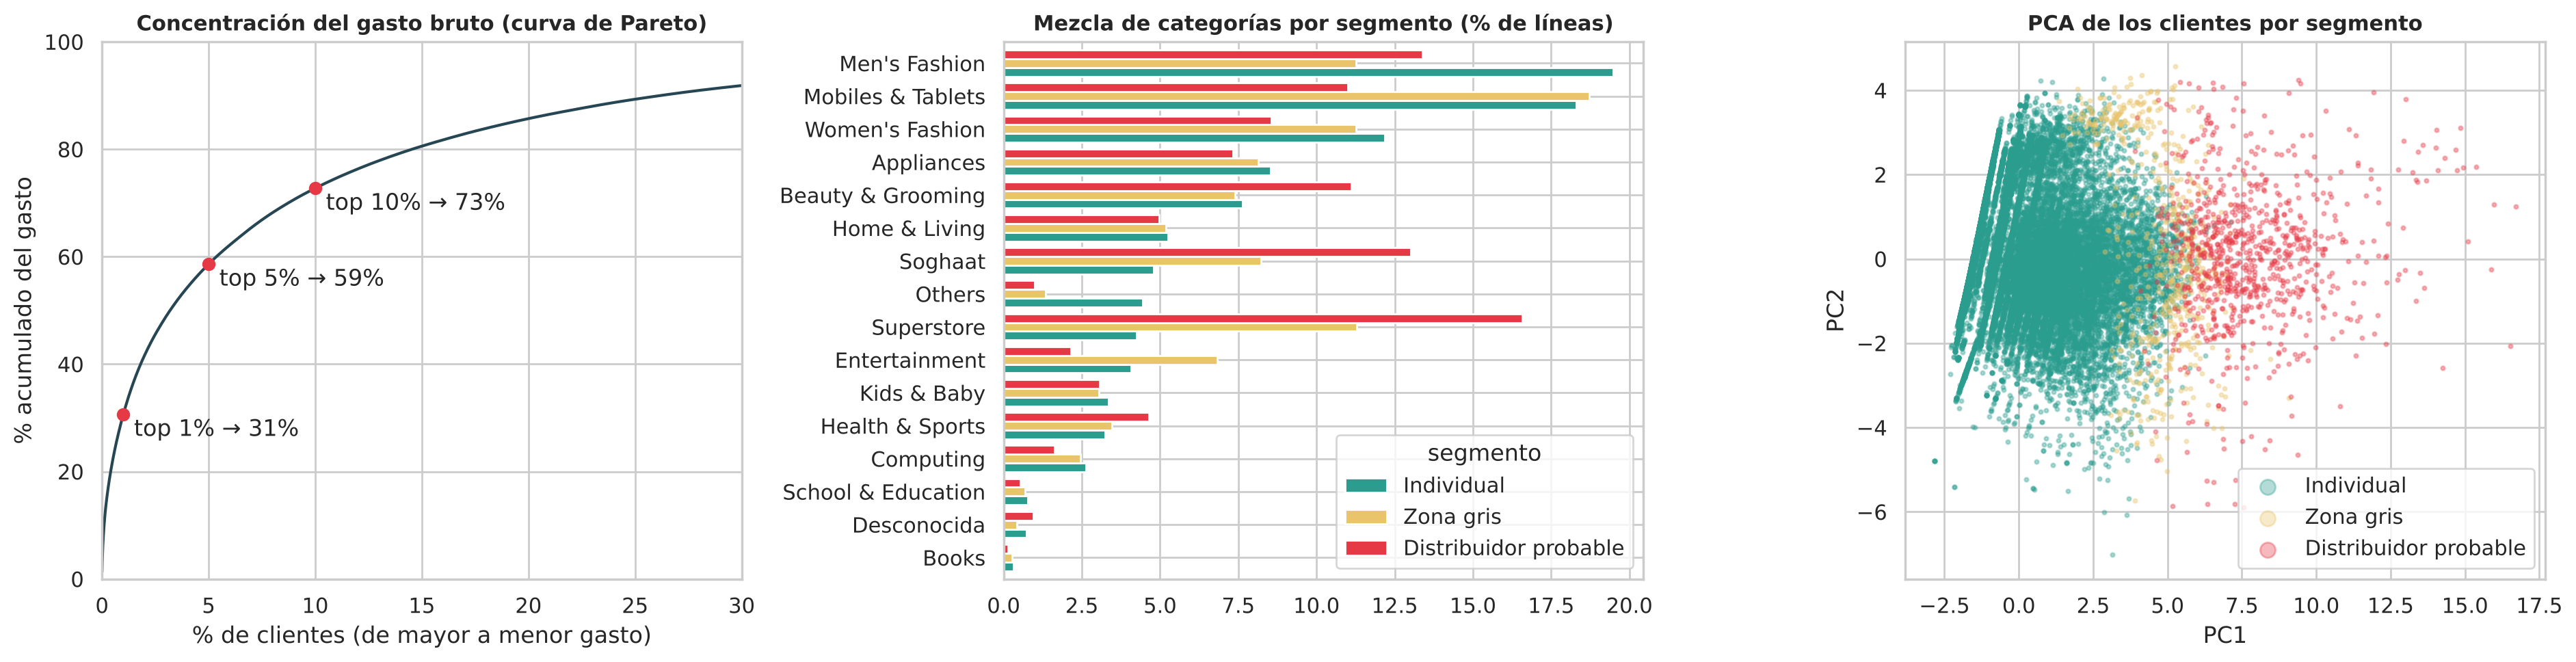

,n_pedidos,unidades,gasto_bruto,ticket_mediano,unidades_por_pedido,max_unidades_pedido,skus_distintos,n_categorias,meses_activos
segmento,,,,,,,,,
Individual,1.0,2.0,2268.0,1404.0,1.0,1.0,1.0,1.0,1.0
Zona gris,10.0,17.0,28717.0,2394.5,2.0,4.0,13.0,4.0,3.0
Distribuidor probable,16.0,39.0,48766.5,1280.0,2.3,8.0,26.0,7.0,6.0


,n_pedidos,unidades,gasto_bruto,ticket_mediano,unidades_por_pedido,max_unidades_pedido,skus_distintos,n_categorias,meses_activos,clientes
tipo_distribuidor,,,,,,,,,,
Comprador de granel,6.0,27.0,17696.0,1658.0,4.9,11.0,21.0,6.0,3.0,299
Distribuidor recurrente,19.0,43.0,59427.0,1224.0,2.0,7.0,28.0,7.0,7.0,1525


In [ ]:
v0["segmento"] = cli0.segmento.reindex(v0.customer_id).values
fig, ax = plt.subplots(1, 3, figsize=(19, 5))

# (a) Pareto del gasto
gs = cli0.gasto_bruto.sort_values(ascending=False).cumsum() / cli0.gasto_bruto.sum() * 100
ax[0].plot(np.arange(1, len(gs) + 1) / len(gs) * 100, gs.values, color=AZUL); ax[0].set(xlim=(0, 30), ylim=(0, 100))
for p in (1, 5, 10):
    y = gs.values[int(len(gs) * p / 100) - 1]; ax[0].scatter(p, y, color="#e63946", zorder=3); ax[0].annotate(f"top {p}% → {y:.0f}%", (p + 0.5, y - 4))
ax[0].set(title="Concentración del gasto bruto (curva de Pareto)", xlabel="% de clientes (de mayor a menor gasto)", ylabel="% acumulado del gasto")

# (b) mezcla de categorías por segmento
mix = (pd.crosstab(v0.category_name_1, v0.segmento, normalize="columns")[list(COL_SEG)] * 100).sort_values("Individual")
mix.plot.barh(ax=ax[1], color=list(COL_SEG.values()), width=0.8); ax[1].set(title="Mezcla de categorías por segmento (% de líneas)", ylabel="")

# (c) PCA
pca_scatter(ax[2], StandardScaler().fit_transform(np.log1p(cli0[FEATS_PCA])), cli0.segmento.values, COL_SEG, 40000, "PCA de los clientes por segmento")
plt.tight_layout(); plt.show()

cols = ["n_pedidos", "unidades", "gasto_bruto", "ticket_mediano", "unidades_por_pedido", "max_unidades_pedido", "skus_distintos", "n_categorias", "meses_activos"]
display(cli0.groupby("segmento")[cols].median().loc[list(COL_SEG)].round(1))
cli0[es_dist].groupby("tipo_distribuidor")[cols].median().round(1).assign(clientes=cli0[es_dist].tipo_distribuidor.value_counts())

**Lectura**
- **Pareto:** el 1 % de los clientes concentra el 31 % del gasto y el 10 %, el 73 % (el 1 % incluye al cliente de PKR 17,9 M).
- **Categorías:** los distribuidores sobrerrepresentan *Superstore* (17 % de sus líneas contra 4 %) y *Soghaat* (13 % contra 5 %): consumo masivo y regalos.
- **PCA:** se separan hacia la derecha en PC1 (intensidad y variedad); la zona gris es una transición continua.
- **Perfil mediano:** el distribuidor hace 16 pedidos y compra 39 unidades, 26 SKUs y 7 categorías; el individuo, 1 pedido de 1 unidad. Su **ticket mediano (PKR 1.280) es igual o menor al del individuo (1.404)**: compran muchas veces cosas chicas y variadas, no pedidos grandes (los de granel sí: 4,9 unidades por pedido).

In [ ]:
# ¿Cuánto distorsionan los distribuidores lo que aprendería un recomendador?
sin_dist = v0[v0.segmento != "Distribuidor probable"]
display(pd.DataFrame({"% de clientes": cli0.segmento.value_counts(normalize=True) * 100,
                      "% de líneas válidas": v0.segmento.value_counts(normalize=True) * 100,
                      "% de unidades": v0.groupby("segmento").qty_ordered.sum() / v0.qty_ordered.sum() * 100}).loc[list(COL_SEG)].round(1))

top20 = lambda d: set(d.groupby("sku").customer_id.nunique().nlargest(20).index)
L_con, L_sin = lift(v0), lift(sin_dist)
n_pares = L_con.shape[0] * (L_con.shape[0] - 1) // 2
print(f"Top-20 de SKUs populares con y sin distribuidores: coinciden {len(top20(v0) & top20(sin_dist))} de 20")
print(f"Lift promedio entre categorías: con distribuidores {np.nanmean(L_con.values):.2f} · sin {np.nanmean(L_sin.values):.2f}")
print(f"Pares de categorías con lift > 1: con distribuidores {(L_con.values > 1).sum() // 2} de {n_pares} · sin {(L_sin.values > 1).sum() // 2}")

,% de clientes,% de líneas válidas,% de unidades
segmento,,,
Individual,96.1,60.7,57.6
Zona gris,1.7,7.3,7.1
Distribuidor probable,2.3,32.0,35.3


Top-20 de SKUs populares con y sin distribuidores: coinciden 18 de 20
Lift promedio entre categorías: con distribuidores 1.59 · sin 1.03
Pares de categorías con lift > 1: con distribuidores 75 de 105 · sin 48


**Evidencia de que conviene sacarlos:** son el 2,3 % de los clientes pero aportan el **32 % de las líneas válidas y el 35 % de las unidades**. En popularidad el efecto es acotado (18 de los 20 SKUs más populares coinciden), pero en la co-compra es grande: el **lift promedio entre categorías baja de 1,59 a 1,03** y los pares "asociados" (lift mayor a 1) pasan de 75 a 48 de 105. Esa asociación falsa es lo que contaminaría a un filtrado colaborativo.

In [ ]:
ids_dist = cli0.index[es_dist]
excluidos = cli0.loc[ids_dist, ["n_pedidos", "n_lineas", "unidades", "gasto_bruto", "ticket_mediano", "max_unidades_pedido", "skus_distintos", "n_categorias", "meses_activos", "n_senales", "tipo_distribuidor"]].copy()

df = df0[~df0.customer_id.isin(ids_dist)].copy()          # <<< DROP: de acá en adelante el análisis usa solo df / v
v = df[df.es_compra_valida].copy()

resumen = lambda d, w: {"transacciones (líneas)": len(d), "líneas válidas": len(w), "pedidos válidos": w.increment_id.nunique(),
                        "clientes con compra válida": w.customer_id.nunique(), "gasto bruto válido (M PKR)": w.monto_bruto.sum() / 1e6}
cmp = pd.DataFrame({"antes": resumen(df0, v0), "después": resumen(df, v)})
cmp["variación %"] = (cmp["después"] / cmp["antes"] - 1) * 100
display(cmp.round(1))

assert not df.customer_id.isin(ids_dist).any() and len(ids_dist) == 1824
excluidos.to_parquet(DIR_SALIDA / "distribuidores_excluidos.parquet")
print(f"Guardado: distribuidores_excluidos.parquet ({len(excluidos):,} clientes)")

,antes,después,variación %
transacciones (líneas),582701.0,422275.0,-27.5
líneas válidas,314565.0,213768.0,-32.0
pedidos válidos,206452.0,147333.0,-28.6
clientes con compra válida,79946.0,78122.0,-2.3
gasto bruto válido (M PKR),1374.9,1062.5,-22.7


Guardado: distribuidores_excluidos.parquet (1,824 clientes)


**Decisión ejecutada:** se excluyen los 1.824 distribuidores (2,3 % de los clientes, pero 32 % de las líneas válidas y 22,7 % del gasto). Quedan 78.122 clientes con compra válida, 147.333 pedidos y 213.768 líneas válidas. **Desde acá `df` y `v` son el dataset sin distribuidores.**

## 3. Tablas base (sin distribuidores)

Tres niveles, porque la unidad cambia la respuesta: **línea** (`df`, `v`), **pedido** (`ped`) y **cliente** (`cli`, solo con compra válida: 78.122). El ticket y los conteos de pedidos se calculan siempre en `ped`, nunca sumando `grand_total` por línea. Se usan las mismas funciones que en la sección 2.

In [ ]:
ped = armar_ped(v)
cli = armar_cli(v, ped)
cli["n_senales_dist"] = cli0.n_senales.reindex(cli.index)                     # señales de distribuidor (0-2: ya sin distribuidores)
cli["zona_gris"] = cli0.segmento.reindex(cli.index) == "Zona gris"

agregar_friccion(cli, df, v)                                                  # canal, pago y fricción

print(f"Pedidos válidos: {len(ped):,} · Clientes con compra válida: {len(cli):,} · Zona gris incluida: {cli.zona_gris.sum():,}")
cli[["n_pedidos", "n_lineas", "unidades", "gasto_bruto", "ticket_mediano", "unidades_por_pedido", "max_unidades_pedido", "skus_distintos", "n_categorias", "meses_activos"]].describe(percentiles=[.5, .9, .99]).T.round(1)[["mean", "50%", "90%", "99%", "max"]]

Pedidos válidos: 147,333 · Clientes con compra válida: 78,122 · Zona gris incluida: 1,323


,mean,50%,90%,99%,max
n_pedidos,1.9,1.0,4.0,10.0,157.0
n_lineas,2.7,1.0,6.0,16.0,237.0
unidades,3.3,2.0,7.0,20.0,390.0
gasto_bruto,13601.1,2379.1,29999.0,195851.1,2508684.0
ticket_mediano,5124.5,1423.0,13613.4,52558.2,1039479.0
unidades_por_pedido,1.7,1.0,3.0,7.3,43.0
max_unidades_pedido,2.0,1.0,4.0,9.0,48.0
skus_distintos,2.4,1.0,5.0,14.0,52.0
n_categorias,1.5,1.0,3.0,5.0,10.0
meses_activos,1.3,1.0,2.0,5.0,14.0


**Lectura:** el cliente típico es muy chico (mediana: 1 pedido, 1 línea, PKR 2.379). Sin distribuidores la cola es mucho más corta (p99: de 20 a 10 pedidos y de ~30 a 14 SKUs; máximo: de 844 a 157 pedidos), pero sigue siendo asimétrica: conviene usar **medianas, percentiles y escala log**.

## 4. Análisis univariado

Categóricas, numéricas por línea, pedido, tiempo y cliente (dataset sin distribuidores).

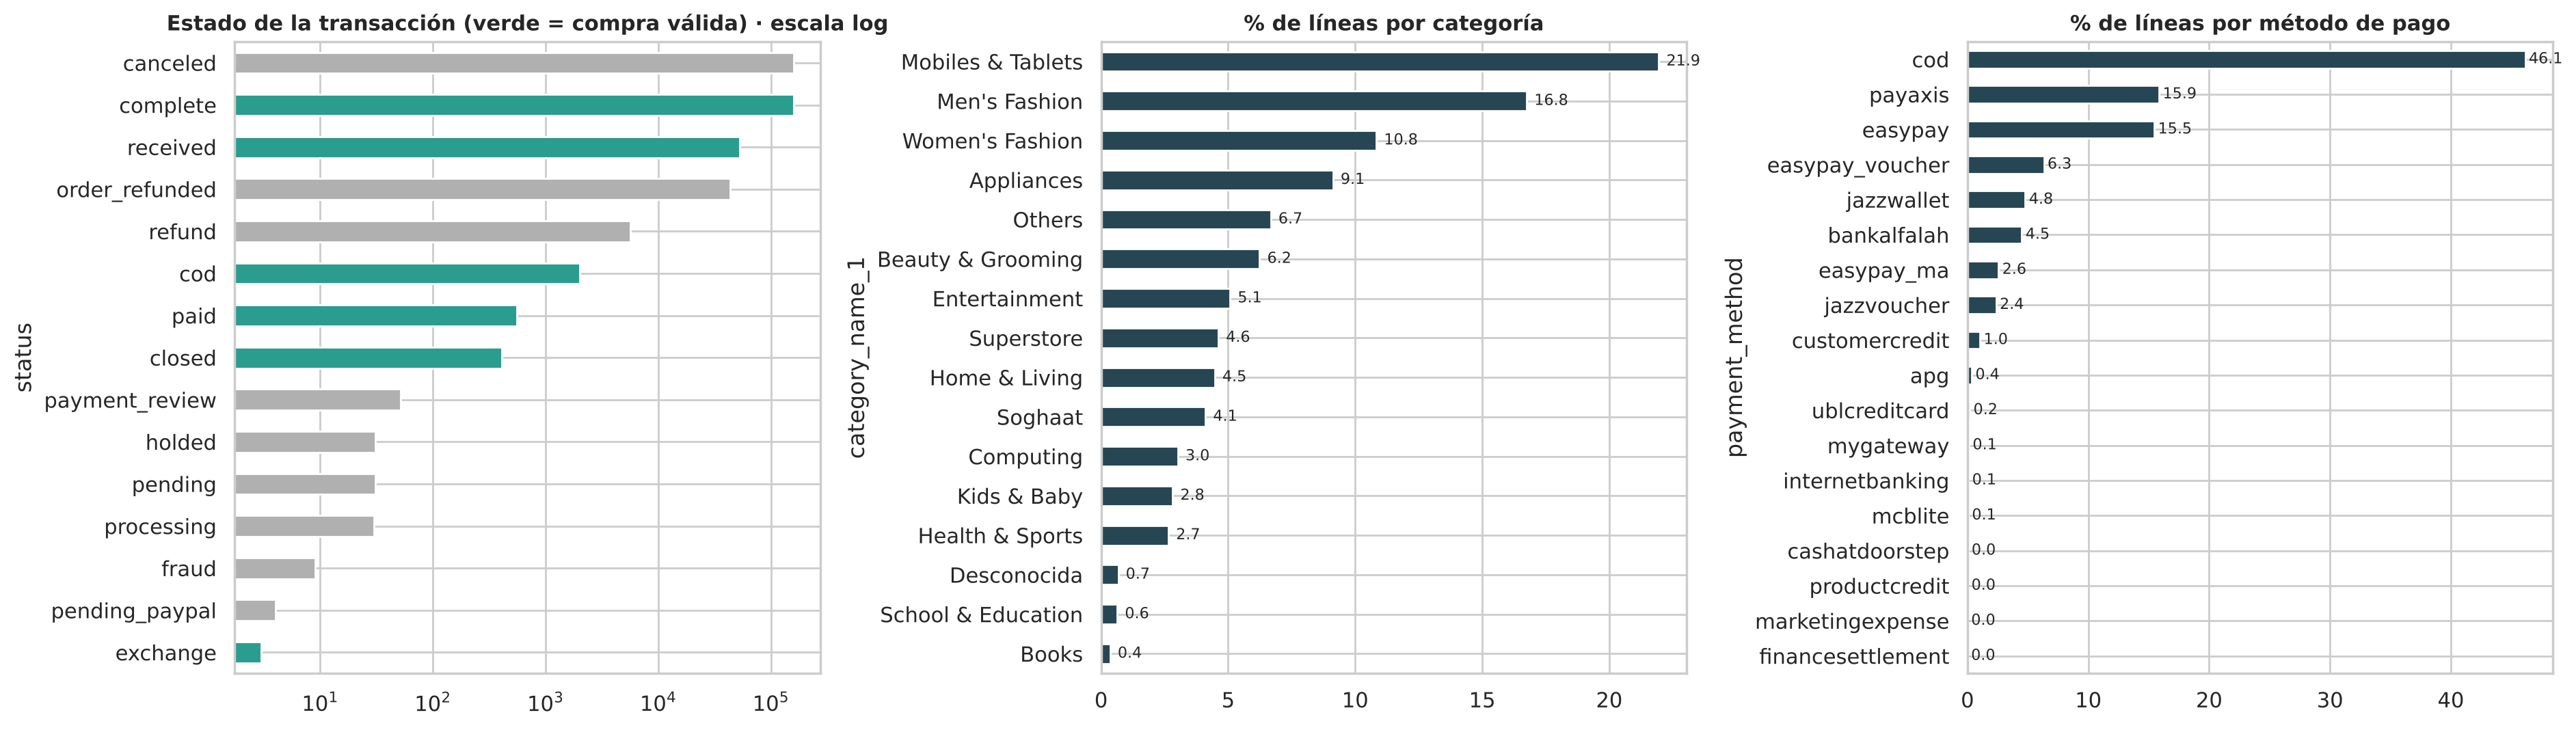

Compras válidas: 50.6% · canceladas: 37.7% · reembolsos: 11.6%


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
est = df.status.value_counts()
est.plot.barh(ax=ax[0], color=["#2a9d8f" if s in VALIDOS else "#b0b0b0" for s in est.index])
ax[0].set_xscale("log"); ax[0].invert_yaxis(); ax[0].set_title("Estado de la transacción (verde = compra válida) · escala log")
for a, col, tit in [(ax[1], "category_name_1", "% de líneas por categoría"), (ax[2], "payment_method", "% de líneas por método de pago")]:
    s = df[col].value_counts(normalize=True) * 100
    s.plot.barh(ax=a, color=AZUL); a.invert_yaxis(); a.set_title(tit)
    for i, x in enumerate(s): a.text(x + 0.3, i, f"{x:.1f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print(f"Compras válidas: {df.es_compra_valida.mean():.1%} · canceladas: {(df.grupo_status == 'cancelada').mean():.1%} · reembolsos: {(df.grupo_status == 'reembolso').mean():.1%}")

**Lectura**
- Solo el **50,6 %** de las transacciones son compras válidas (37,7 % se cancela y 11,6 % se reembolsa).
- El catálogo está concentrado: *Mobiles & Tablets* (21,9 %), *Men's Fashion* (16,8 %) y *Women's Fashion* (10,8 %) suman casi la mitad de las líneas.
- **Contra entrega (`cod`) es el método más usado (46,1 %)**, seguido por payaxis (15,9 %) y easypay (15,5 %).

,count,mean,std,min,50%,90%,99%,max,asimetría
price,213768.0,4513.7,10463.8,0.2,827.5,14000.0,55250.0,189691.0,5.0
qty_ordered,213768.0,1.2,0.7,1.0,1.0,2.0,5.0,40.0,10.3
monto_bruto,213768.0,4970.6,12225.7,0.4,899.0,14000.0,60000.0,1039479.0,9.0
discount_amount,213768.0,544.9,1534.7,0.0,0.0,2000.0,7000.0,29025.0,4.7


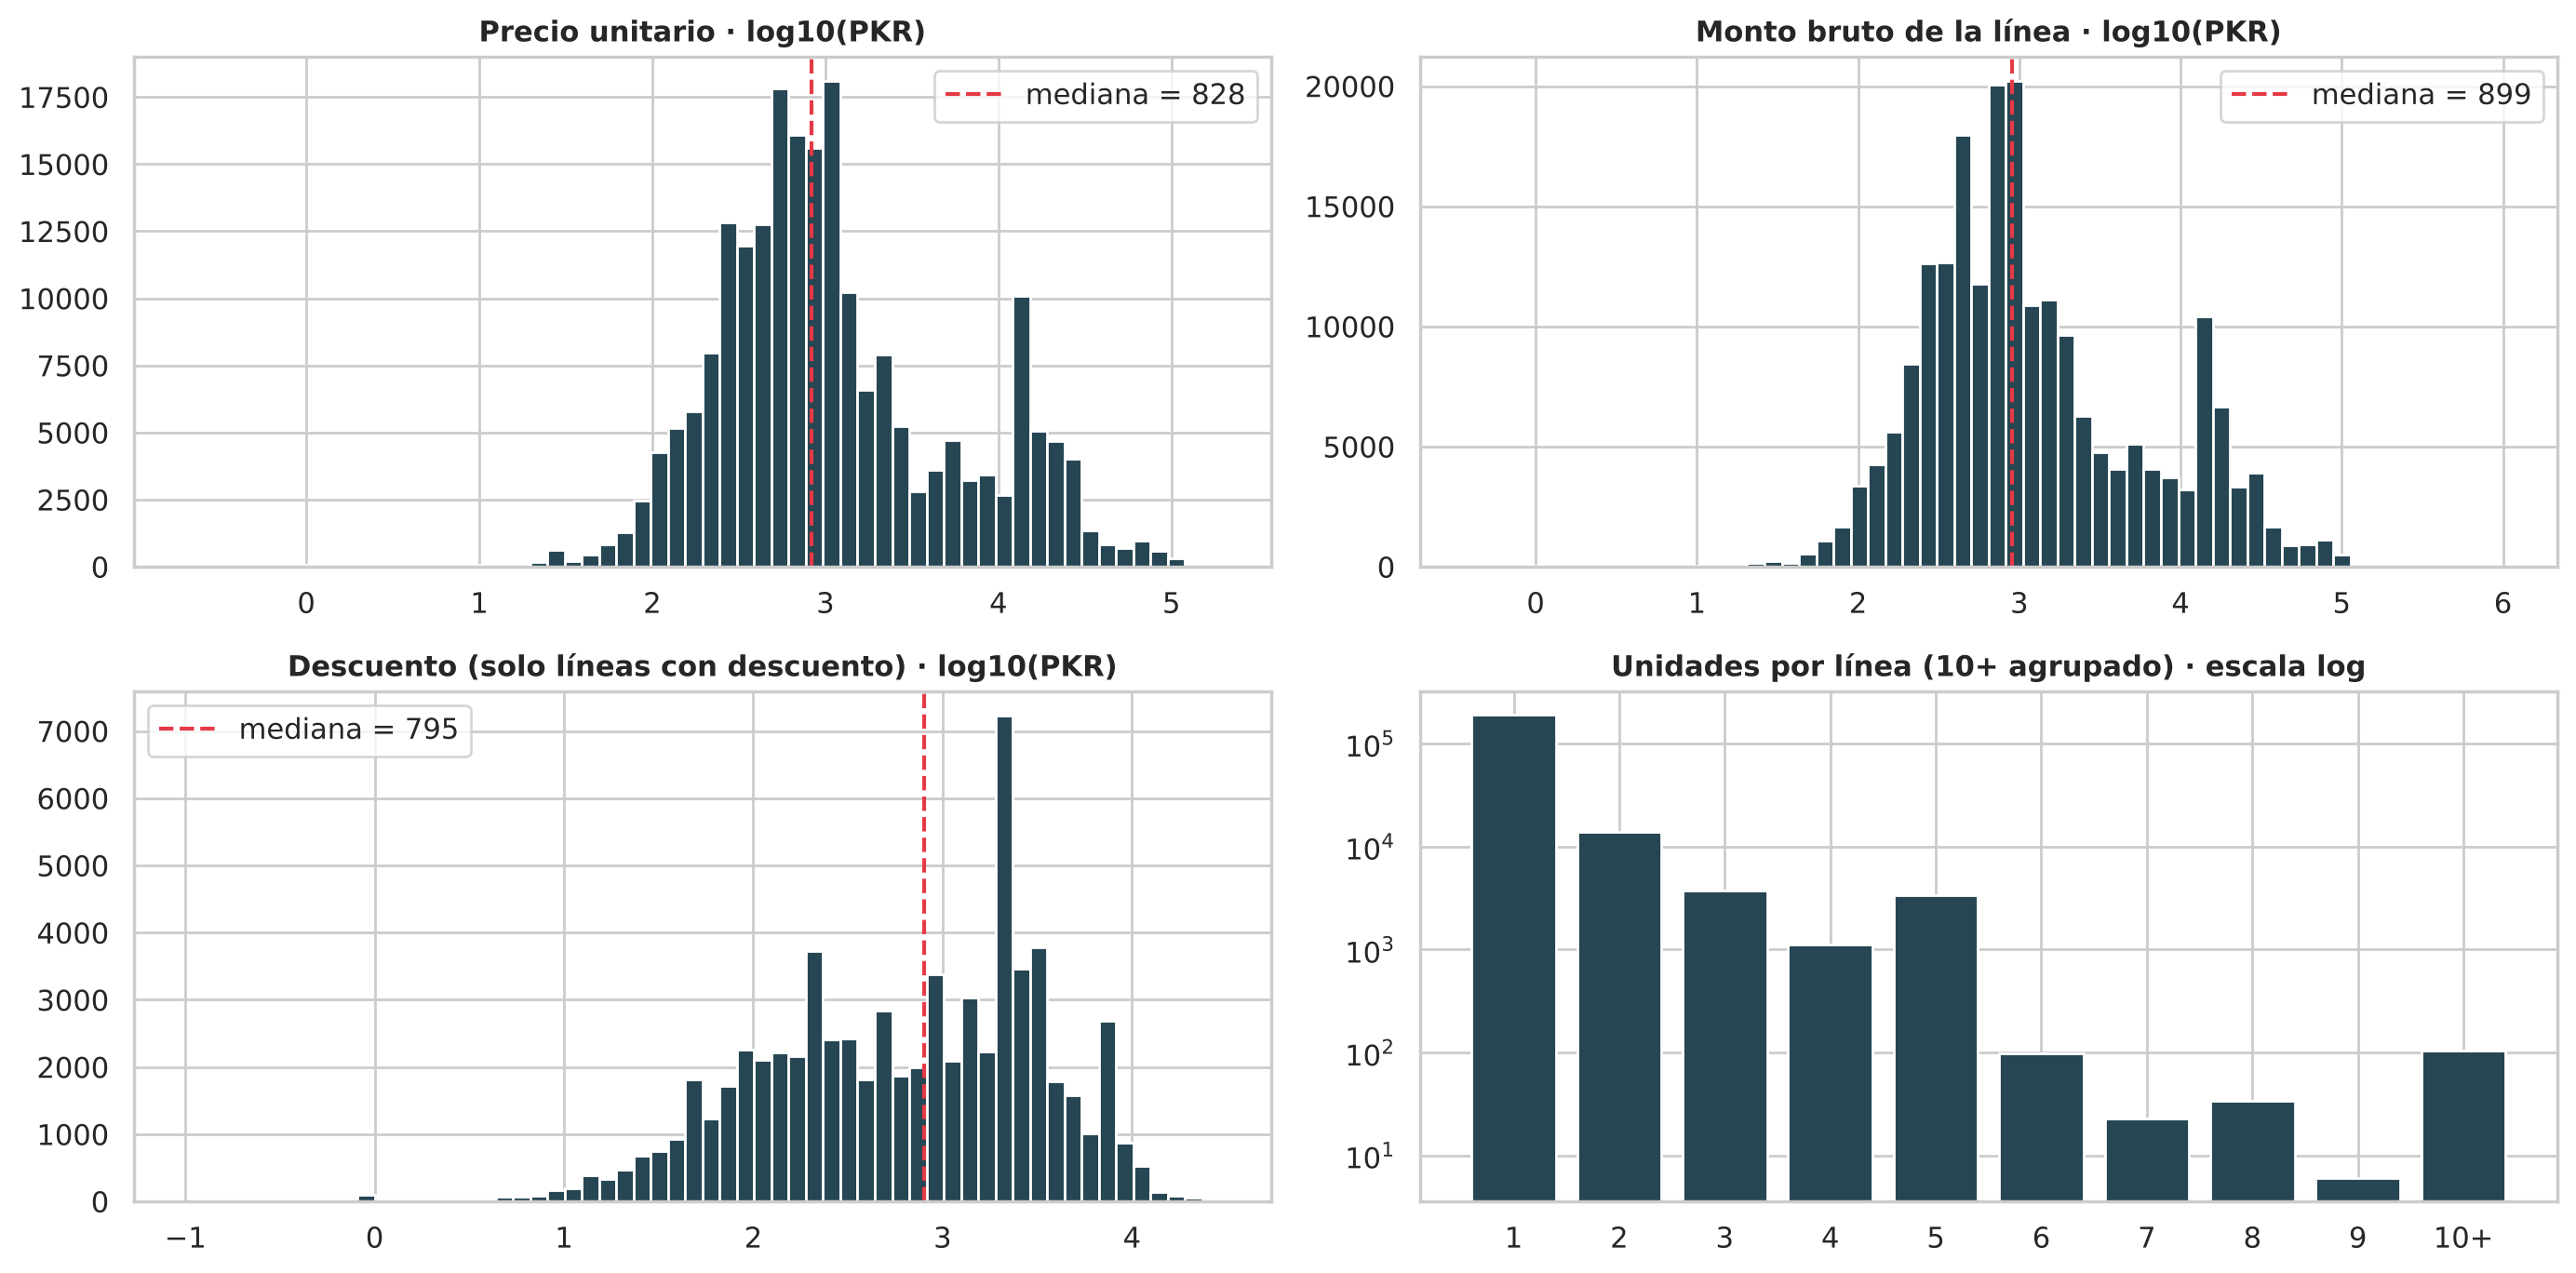

Líneas con 1 unidad: 89.6% · con descuento: 32.2% · líneas de 4 / 5 unidades: 1,124 / 3,391


In [ ]:
num = v[["price", "qty_ordered", "monto_bruto", "discount_amount"]].astype(float)
display(num.describe(percentiles=[.5, .9, .99]).T.assign(asimetría=num.skew()).round(1))

fig, ax = plt.subplots(2, 2, figsize=(14, 7))
hist_log(ax[0, 0], v.price, "Precio unitario · log10(PKR)")
hist_log(ax[0, 1], v.monto_bruto, "Monto bruto de la línea · log10(PKR)")
hist_log(ax[1, 0], v.discount_amount, "Descuento (solo líneas con descuento) · log10(PKR)")
barras_cap(ax[1, 1], v.qty_ordered, 10, "Unidades por línea (10+ agrupado) · escala log", log=True)
plt.tight_layout(); plt.show()
q = v.qty_ordered.value_counts()
print(f"Líneas con 1 unidad: {(v.qty_ordered == 1).mean():.1%} · con descuento: {(v.discount_amount > 0).mean():.1%} · líneas de 4 / 5 unidades: {q[4]:,} / {q[5]:,}")

**Lectura**
- Precio y monto son muy asimétricos (asimetría de 5 y 9): mediana de PKR 828 y percentil 90 de PKR 14.000. Conviene `log(precio)` o el precio relativo a la categoría.
- El **89,6 %** de las líneas es de una unidad. Hay un pico anómalo en **5 unidades** (3.391 líneas contra 1.124 en 4), que parecen packs; las líneas de varias unidades se concentran en *Others* y *Superstore* (sección 5).
- El 32,2 % de las líneas tiene descuento, pero `discount_amount` no es confiable por línea; para volumen se usa `monto_bruto`.

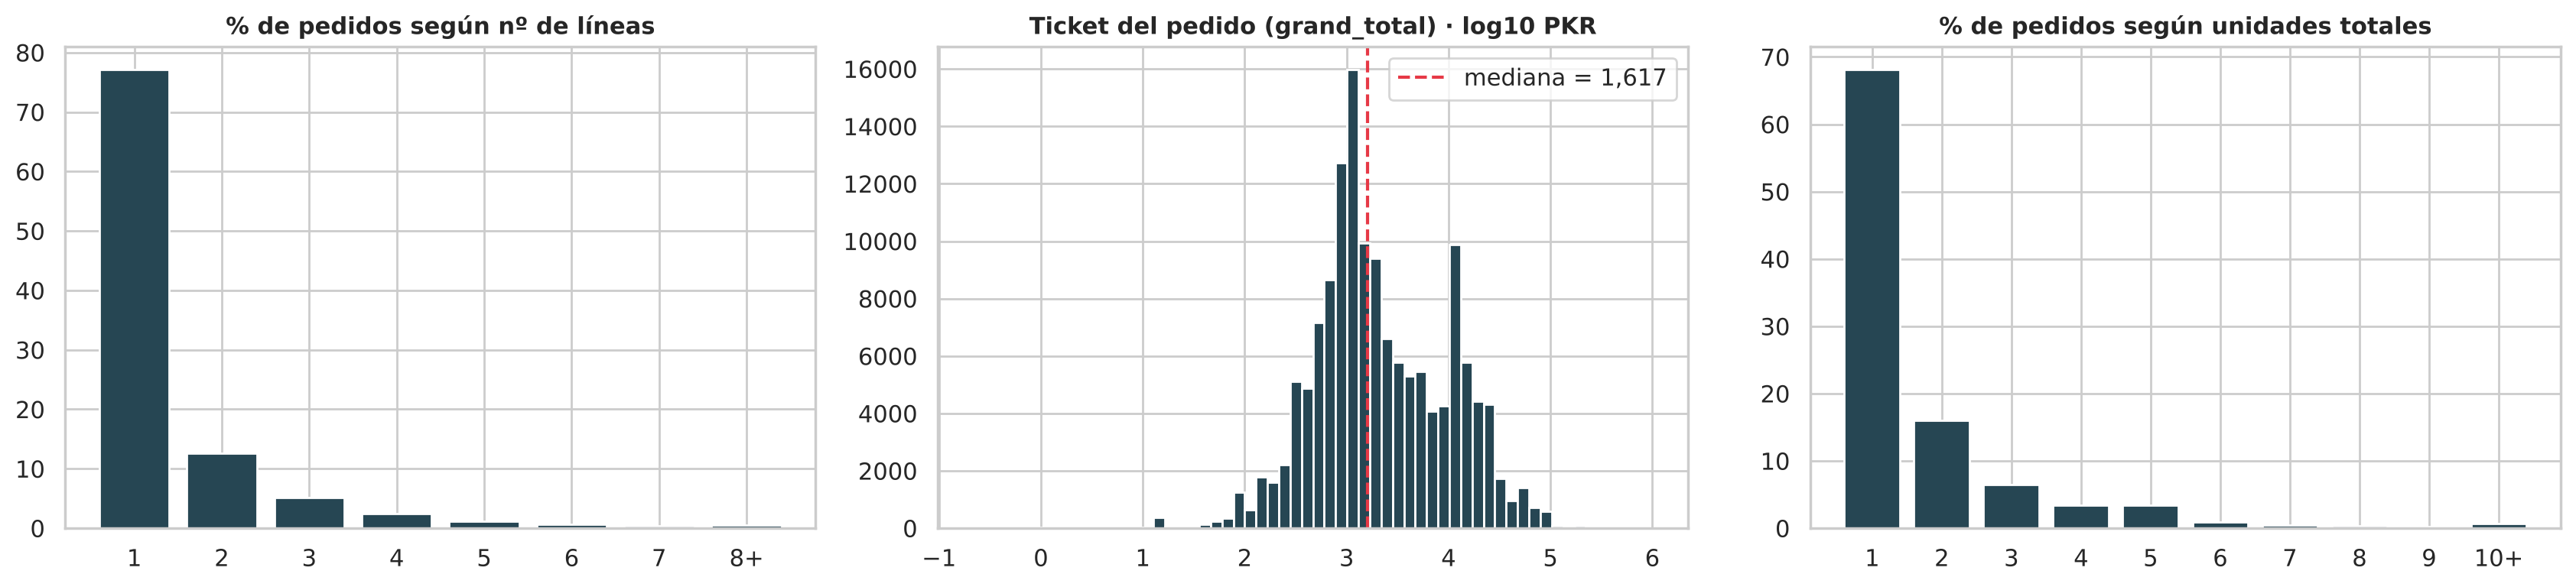

,count,mean,std,min,50%,90%,99%,max
lineas,147333.0,1.5,1.2,1.0,1.0,3.0,6.0,38.0
unidades,147333.0,1.7,1.7,1.0,1.0,3.0,8.0,48.0
grand_total,147333.0,6378.4,13369.2,-168.4,1549.0,16899.0,61813.0,1039479.0


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
barras_cap(ax[0], ped.lineas, 8, "% de pedidos según nº de líneas", pct=True)
hist_log(ax[1], ped.grand_total, "Ticket del pedido (grand_total) · log10 PKR")
barras_cap(ax[2], ped.unidades, 10, "% de pedidos según unidades totales", pct=True)
plt.tight_layout(); plt.show()
ped[["lineas", "unidades", "grand_total"]].describe(percentiles=[.5, .9, .99]).round(1).T

**Lectura:** el pedido típico es chico: mediana de 1 línea y 1 unidad, ticket mediano de PKR 1.549 (p99: PKR 61.813). El 90 % tiene 3 líneas o menos, así que **la co-compra dentro de un mismo pedido es una señal escasa**.

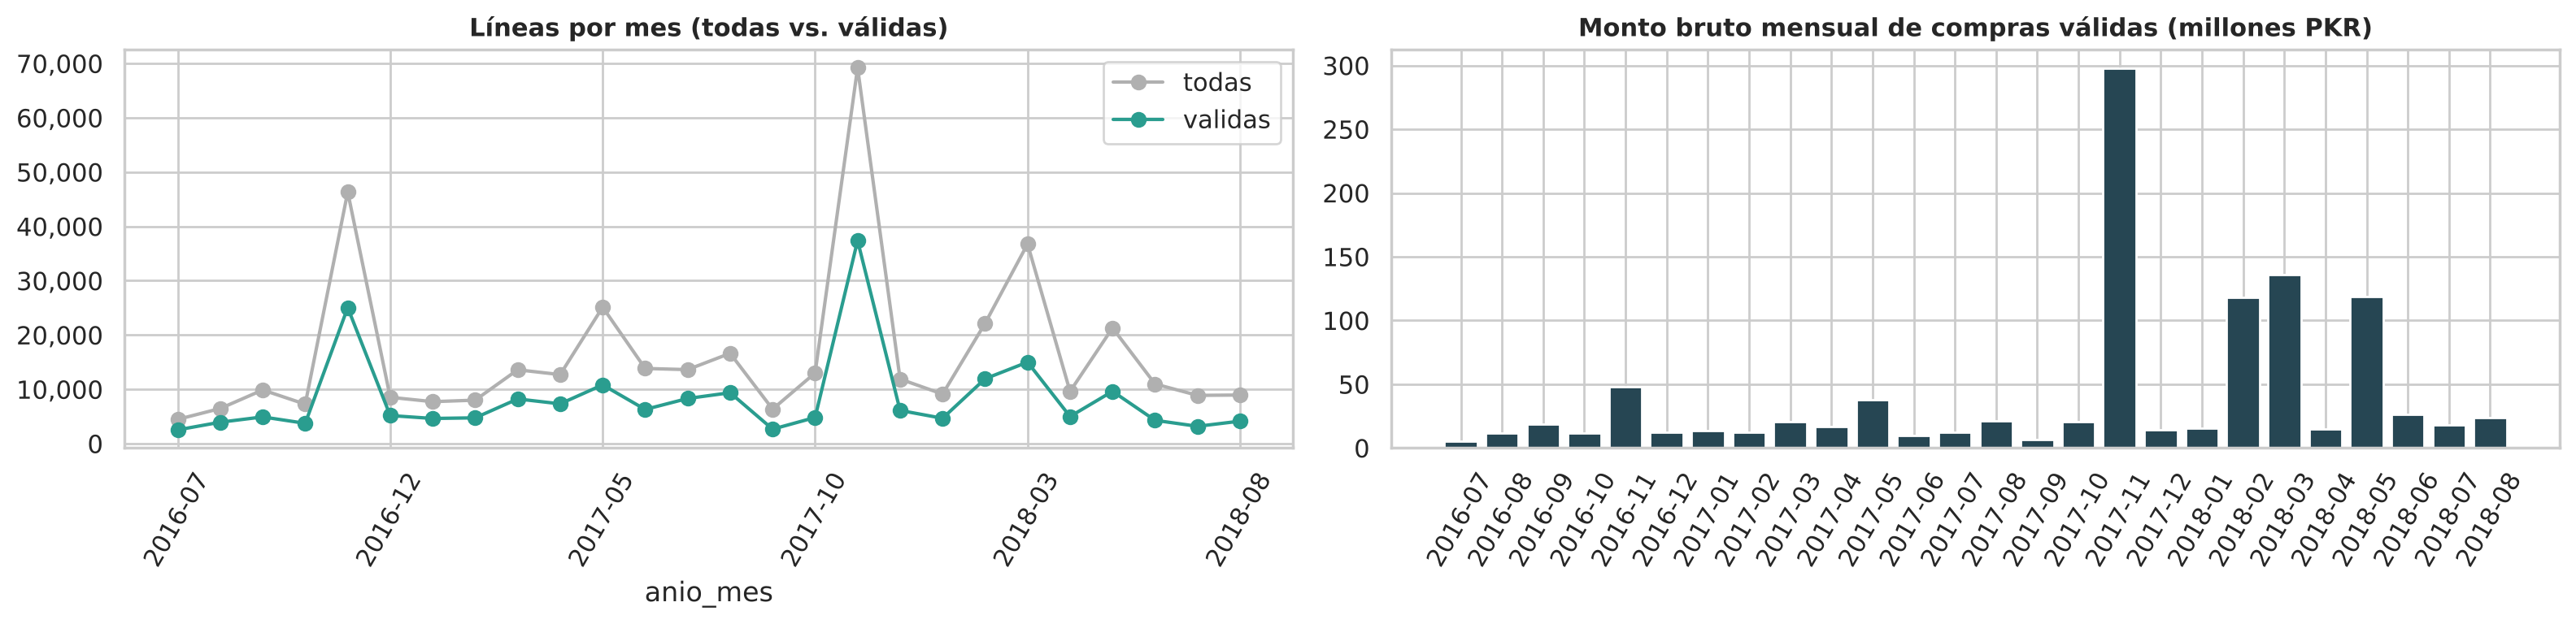

,todas,validas,bruto_M
anio_mes,,,
2017-11,69209,37380,297.5
2016-11,46332,25038,48.3
2018-03,36751,14995,135.7
2018-02,22134,11935,118.3


In [ ]:
mes = df.groupby("anio_mes").agg(todas=("item_id", "size"), validas=("es_compra_valida", "sum"))
mes["bruto_M"] = v.groupby("anio_mes").monto_bruto.sum() / 1e6
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
mes[["todas", "validas"]].plot(ax=ax[0], marker="o", color=["#b0b0b0", "#2a9d8f"]); ax[0].set_title("Líneas por mes (todas vs. válidas)")
ax[0].yaxis.set_major_formatter("{x:,.0f}"); ax[0].tick_params(axis="x", rotation=60)
ax[1].bar(mes.index, mes.bruto_M, color=AZUL); ax[1].set_title("Monto bruto mensual de compras válidas (millones PKR)"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
mes.nlargest(4, "validas")[["todas", "validas", "bruto_M"]].round(1)

**Lectura:** el período va de **julio 2016 a agosto 2018**, con picos en **noviembre** (¿11.11 / Black Friday?): 25.038 líneas válidas en 2016-11 y 37.380 en 2017-11, con un monto bruto unas 6 veces mayor (PKR 298 M contra 48 M), y un pico menor en febrero-marzo de 2018. El negocio creció y es estacional: el split temporal no puede ignorar noviembre y la popularidad histórica queda sesgada hacia esos picos.

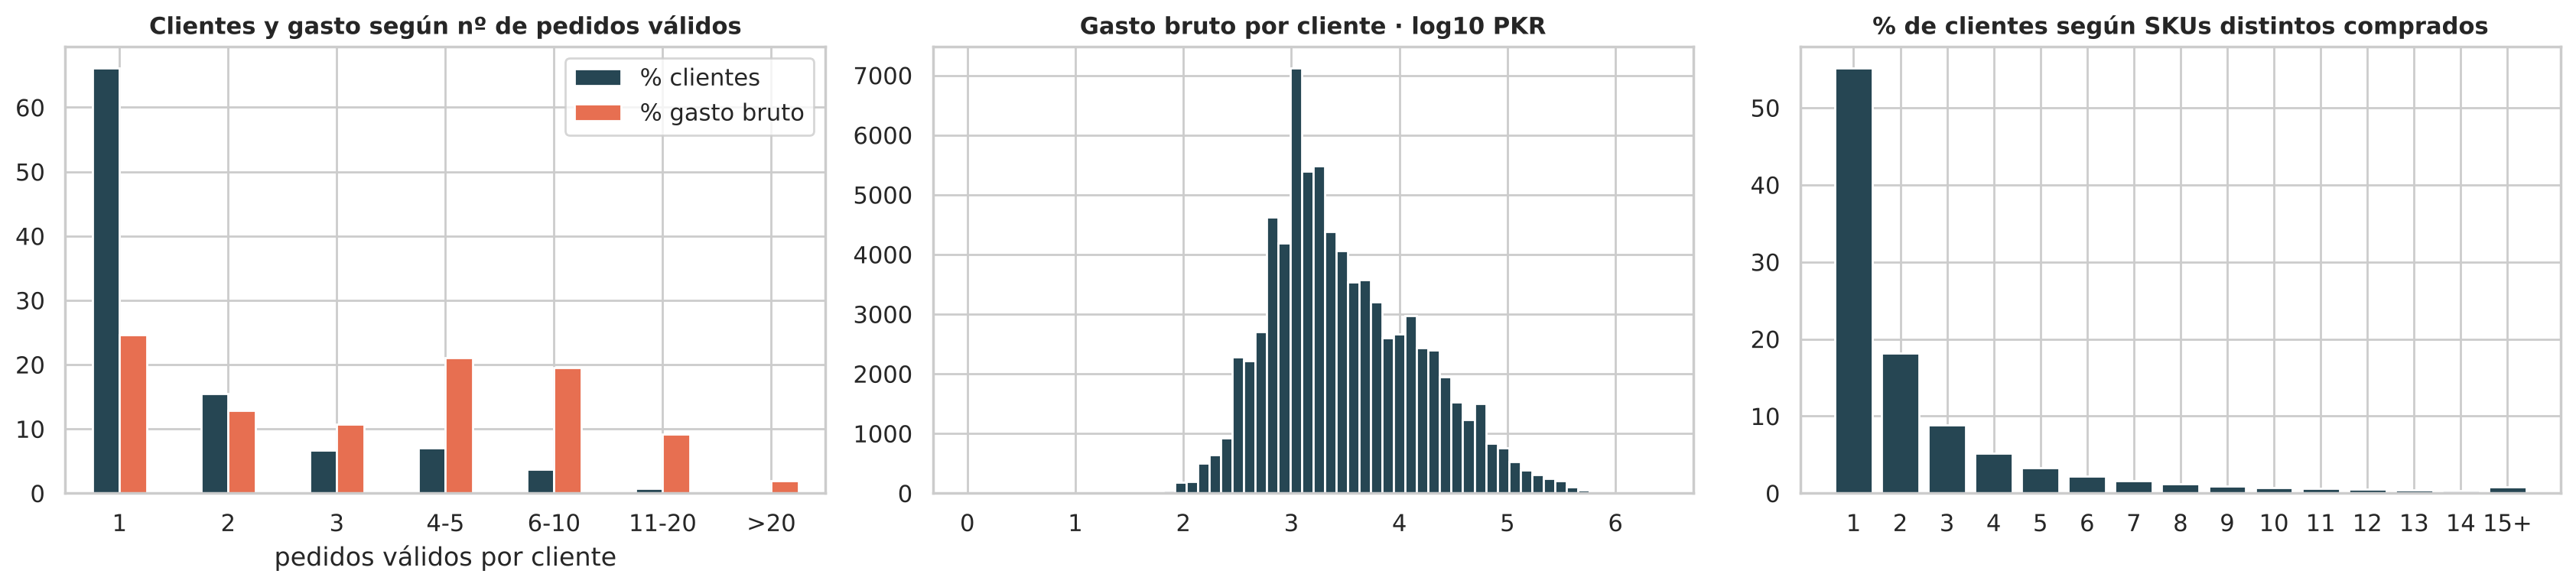

               clientes  % clientes  % gasto bruto
tramo_pedidos                                     
1                 51662        66.1           24.6
2                 12097        15.5           12.9
3                  5243         6.7           10.8
4-5                5492         7.0           21.1
6-10               2940         3.8           19.5
11-20               610         0.8            9.2
>20                  78         0.1            1.9

Clientes con un único pedido: 66.1% · con un único SKU: 55.2% · con un solo producto y una sola unidad: 44.2%


In [ ]:
cli["tramo_pedidos"] = pd.cut(cli.n_pedidos, [0, 1, 2, 3, 5, 10, 20, np.inf], labels=["1", "2", "3", "4-5", "6-10", "11-20", ">20"])
t = cli.groupby("tramo_pedidos", observed=True).agg(clientes=("gasto_bruto", "size"), gasto=("gasto_bruto", "sum"))
t["% clientes"] = t.clientes / t.clientes.sum() * 100; t["% gasto bruto"] = t.gasto / t.gasto.sum() * 100

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
t[["% clientes", "% gasto bruto"]].plot.bar(ax=ax[0], color=[AZUL, "#e76f51"], rot=0); ax[0].set(title="Clientes y gasto según nº de pedidos válidos", xlabel="pedidos válidos por cliente")
hist_log(ax[1], cli.gasto_bruto, "Gasto bruto por cliente · log10 PKR", mediana=False)
barras_cap(ax[2], cli.skus_distintos, 15, "% de clientes según SKUs distintos comprados", pct=True)
plt.tight_layout(); plt.show()
print(t[["clientes", "% clientes", "% gasto bruto"]].round(1))
print(f"\nClientes con un único pedido: {(cli.n_pedidos == 1).mean():.1%} · con un único SKU: {(cli.skus_distintos == 1).mean():.1%} · con un solo producto y una sola unidad: {((cli.skus_distintos == 1) & (cli.unidades == 1)).mean():.1%}")

**Lectura**
- **El 66,1 % de los clientes compró una sola vez** y el 44 % compró un único producto en una sola unidad: cold start severo.
- Esos clientes de 1 pedido son dos tercios de la base pero solo el **24,6 %** del gasto, mientras que el 4,7 % con 6 o más pedidos genera el **30,6 %**. La recurrencia concentra el valor y es la base de la sección 7.

In [ ]:
flags = ["precio_cero", "descuento_inconsistente", "grand_total_negativo", "qty_atipica", "uso_codigo_comision", "cuenta_interna_probable"]
pd.DataFrame({"% de todas las líneas": df[flags].mean() * 100, "% de líneas válidas": v[flags].mean() * 100}).round(2)

,% de todas las líneas,% de líneas válidas
precio_cero,0.39,0.00
descuento_inconsistente,1.33,1.70
grand_total_negativo,0.01,0.00
qty_atipica,0.00,0.00
uso_codigo_comision,11.36,13.78
cuenta_interna_probable,0.21,0.04


**Lectura:** las banderas son poco frecuentes. La relevante es `uso_codigo_comision`: el **13,8 %** de las líneas válidas pasa por un código de vendedor o afiliado. Las cuentas internas son el 0,04 % de las líneas válidas, pero conviene excluirlas de rankings de clientes.

## 5. Análisis bivariado

Qué categorías y métodos de pago terminan en compra, precio, cantidad y descuento por categoría, y estacionalidad.

category_name_1 · % compra válida: {'Others': 31.0, 'Mobiles & Tablets': 42.0, 'Entertainment': 43.0, 'Computing': 44.0, 'Appliances': 47.0, 'Desconocida': 53.0, 'Superstore': 55.0, "Men's Fashion": 56.0, "Women's Fashion": 57.0, 'Home & Living': 59.0, 'Kids & Baby': 60.0, 'School & Education': 61.0, 'Beauty & Grooming': 62.0, 'Health & Sports': 62.0, 'Soghaat': 64.0, 'Books': 71.0}
payment_method · % compra válida: {'mygateway': 1.0, 'apg': 18.0, 'ublcreditcard': 21.0, 'bankalfalah': 23.0, 'easypay_ma': 25.0, 'payaxis': 28.0, 'easypay': 29.0, 'jazzwallet': 40.0, 'jazzvoucher': 41.0, 'easypay_voucher': 60.0, 'cod': 70.0, 'customercredit': 82.0}


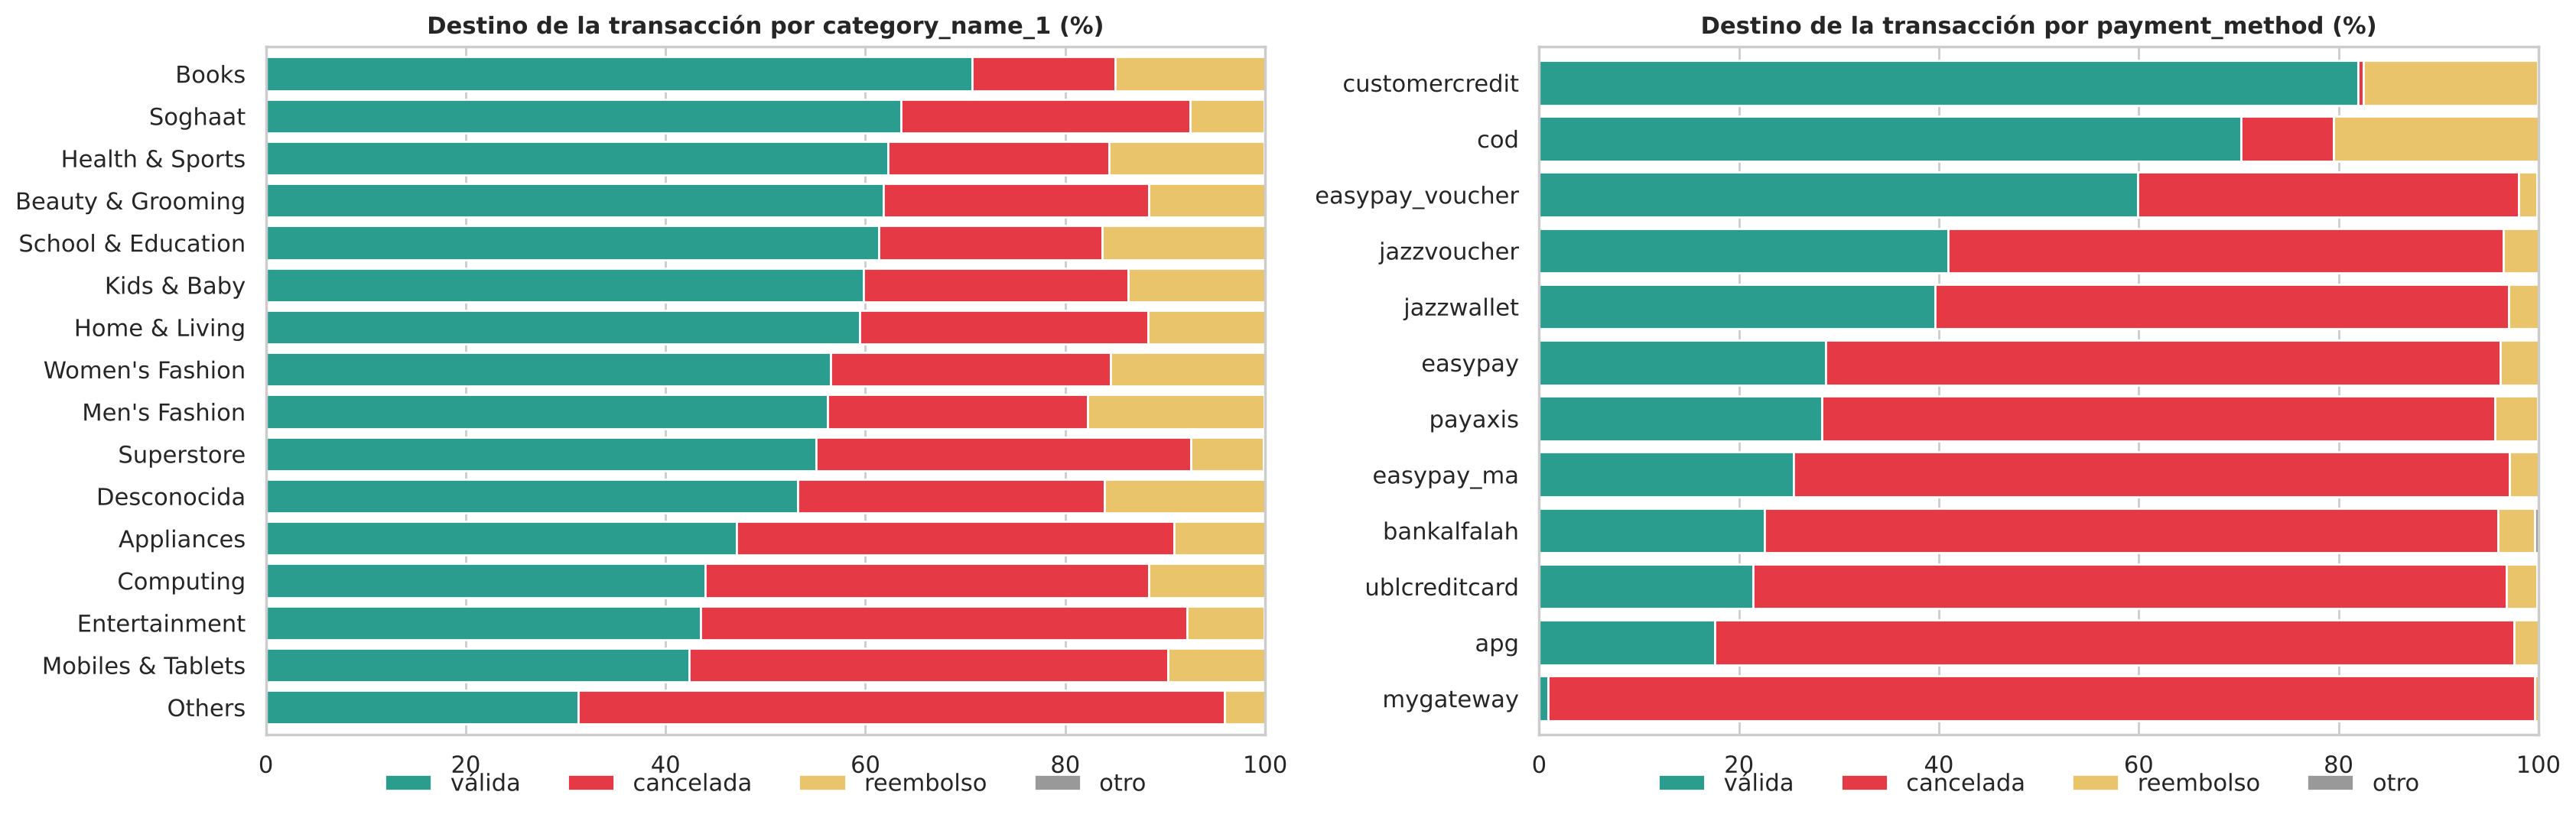

In [ ]:
ORDEN = ["válida", "cancelada", "reembolso", "otro"]
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
for a, col in zip(ax, ["category_name_1", "payment_method"]):
    cnt = df[col].value_counts(); sub = df[df[col].isin(cnt[cnt >= 500].index)]
    tb = (pd.crosstab(sub[col], sub.grupo_status, normalize="index") * 100)[ORDEN].sort_values("válida")
    tb.plot.barh(stacked=True, ax=a, color=["#2a9d8f", "#e63946", "#e9c46a", "#999999"], width=0.8)
    a.set(xlim=(0, 100), title=f"Destino de la transacción por {col} (%)", ylabel="")
    a.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.12), frameon=False)
    print(f"{col} · % compra válida:", tb["válida"].round(0).to_dict())
plt.tight_layout(); plt.show()

**Lectura**
- **El método de pago pesa mucho más que la categoría:** por categoría la tasa de compra válida va del 31 % al 71 %; por método, del **1 % al 82 %**. Con crédito del cliente (82 %) y contra entrega (70 %, con 20,5 % de reembolsos) casi todo se concreta; con pagos online (apg, ublcreditcard, bankalfalah, easypay, payaxis) solo el 18-29 %, y `mygateway` casi nunca.
- Por categoría concretan más *Books* (71 %) y *Soghaat* (64 %), y menos *Others* (31 %), *Mobiles & Tablets* (42 %) y *Entertainment* (43 %).
- Filtrar `es_compra_valida` es imprescindible: sin eso el modelo aprendería productos que la gente abandona.

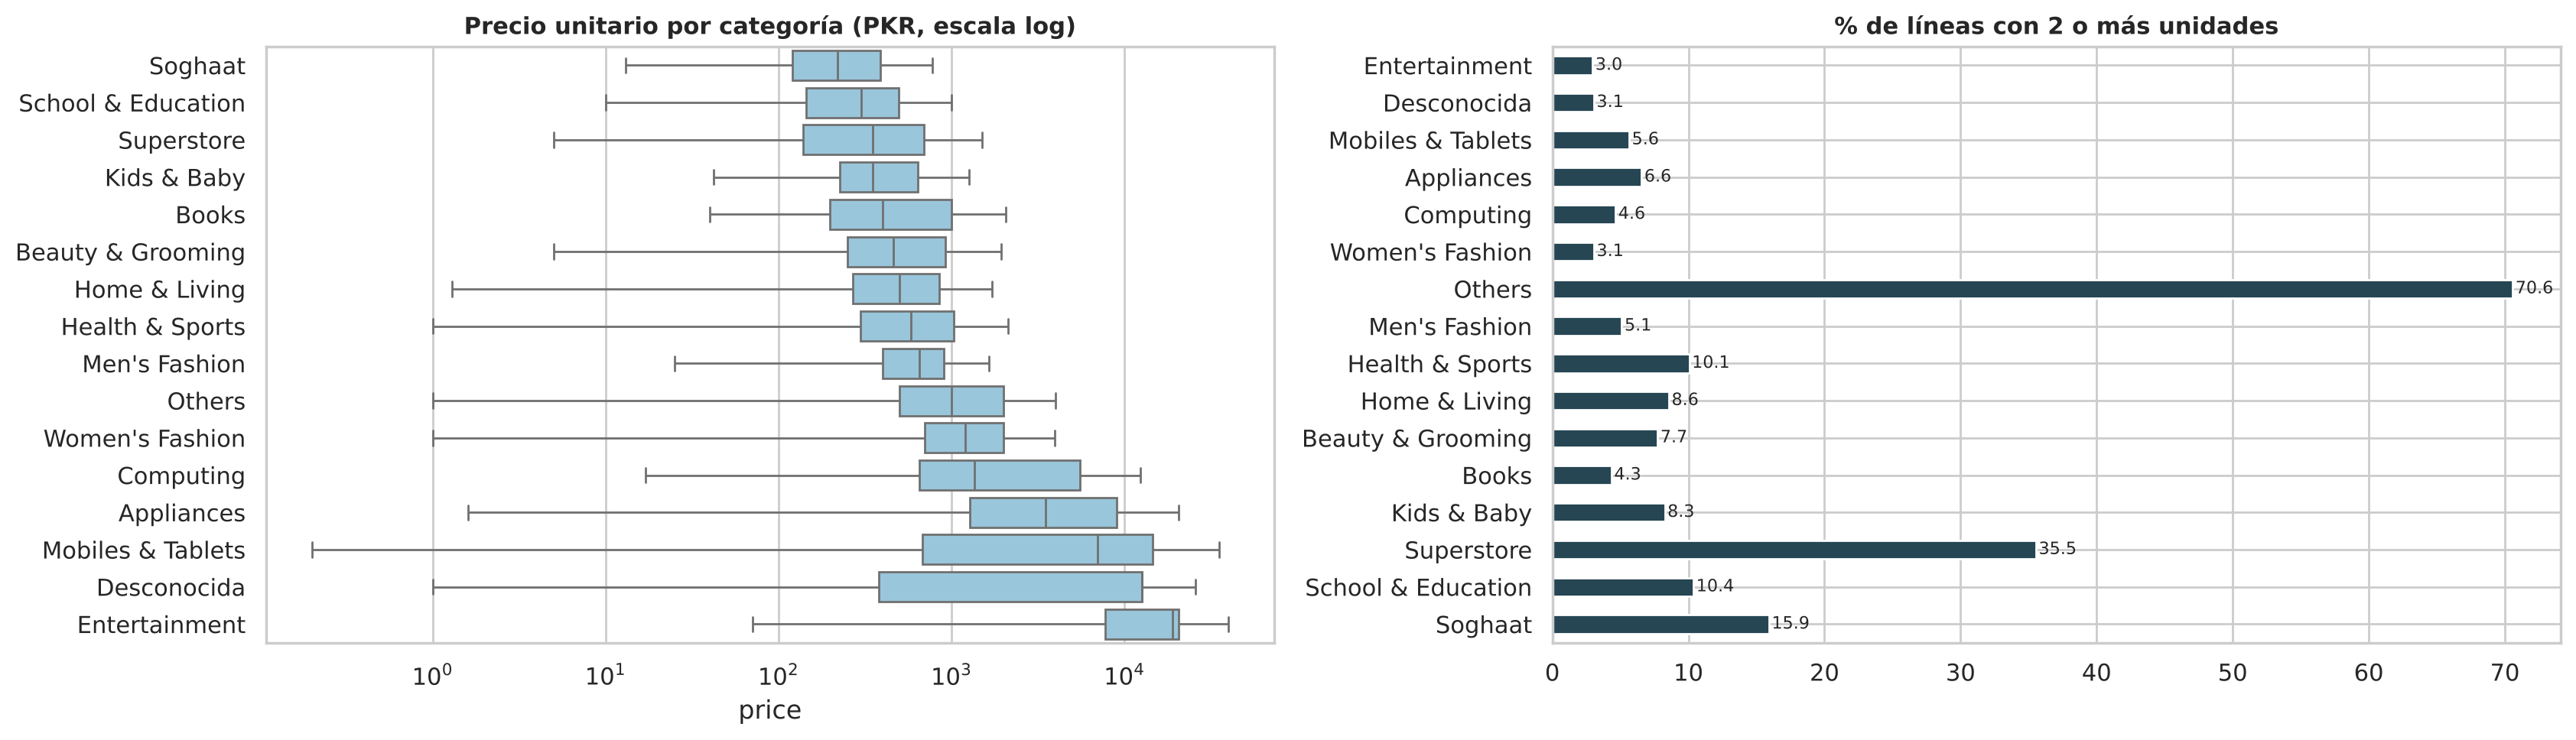

category_name_1,Soghaat,School & Education,Superstore,Kids & Baby,Books,Beauty & Grooming,Home & Living,Health & Sports,Men's Fashion,Others,Women's Fashion,Computing,Appliances,Mobiles & Tablets,Desconocida,Entertainment
pct_multi,15.9,10.4,35.5,8.3,4.3,7.7,8.6,10.1,5.1,70.6,3.1,4.6,6.6,5.6,3.1,3.0
precio_mediano,220.0,300.0,349.0,350.0,400.0,462.0,499.0,585.0,649.0,1000.0,1200.0,1350.0,3508.0,6999.0,12599.0,18960.0


In [ ]:
orden = v.groupby("category_name_1").price.median().sort_values().index
rep = v.groupby("category_name_1").agg(pct_multi=("qty_ordered", lambda s: (s >= 2).mean() * 100), precio_mediano=("price", "median")).loc[orden]
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
sns.boxplot(data=v, y="category_name_1", x="price", order=orden, showfliers=False, color="#8ecae6", ax=ax[0])
ax[0].set(xscale="log", title="Precio unitario por categoría (PKR, escala log)", ylabel="")
rep.pct_multi.plot.barh(ax=ax[1], color=AZUL); ax[1].set(title="% de líneas con 2 o más unidades", ylabel="")
for i, x in enumerate(rep.pct_multi): ax[1].text(x + 0.2, i, f"{x:.1f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()
rep.round(1).T

**Lectura**
- Caras: *Entertainment* (mediana PKR 18.960), *Mobiles & Tablets* (6.999), *Appliances* (3.508) y *Computing* (1.350). Baratas: *Soghaat* (220), *School & Education* (300), *Superstore* (349) y *Kids & Baby* (350). La categoría ya dice mucho del rango de precio.
- Compra por cantidad: *Others* (71 % de las líneas con 2 o más unidades) y *Superstore* (36 %); en el resto, 3-16 %.

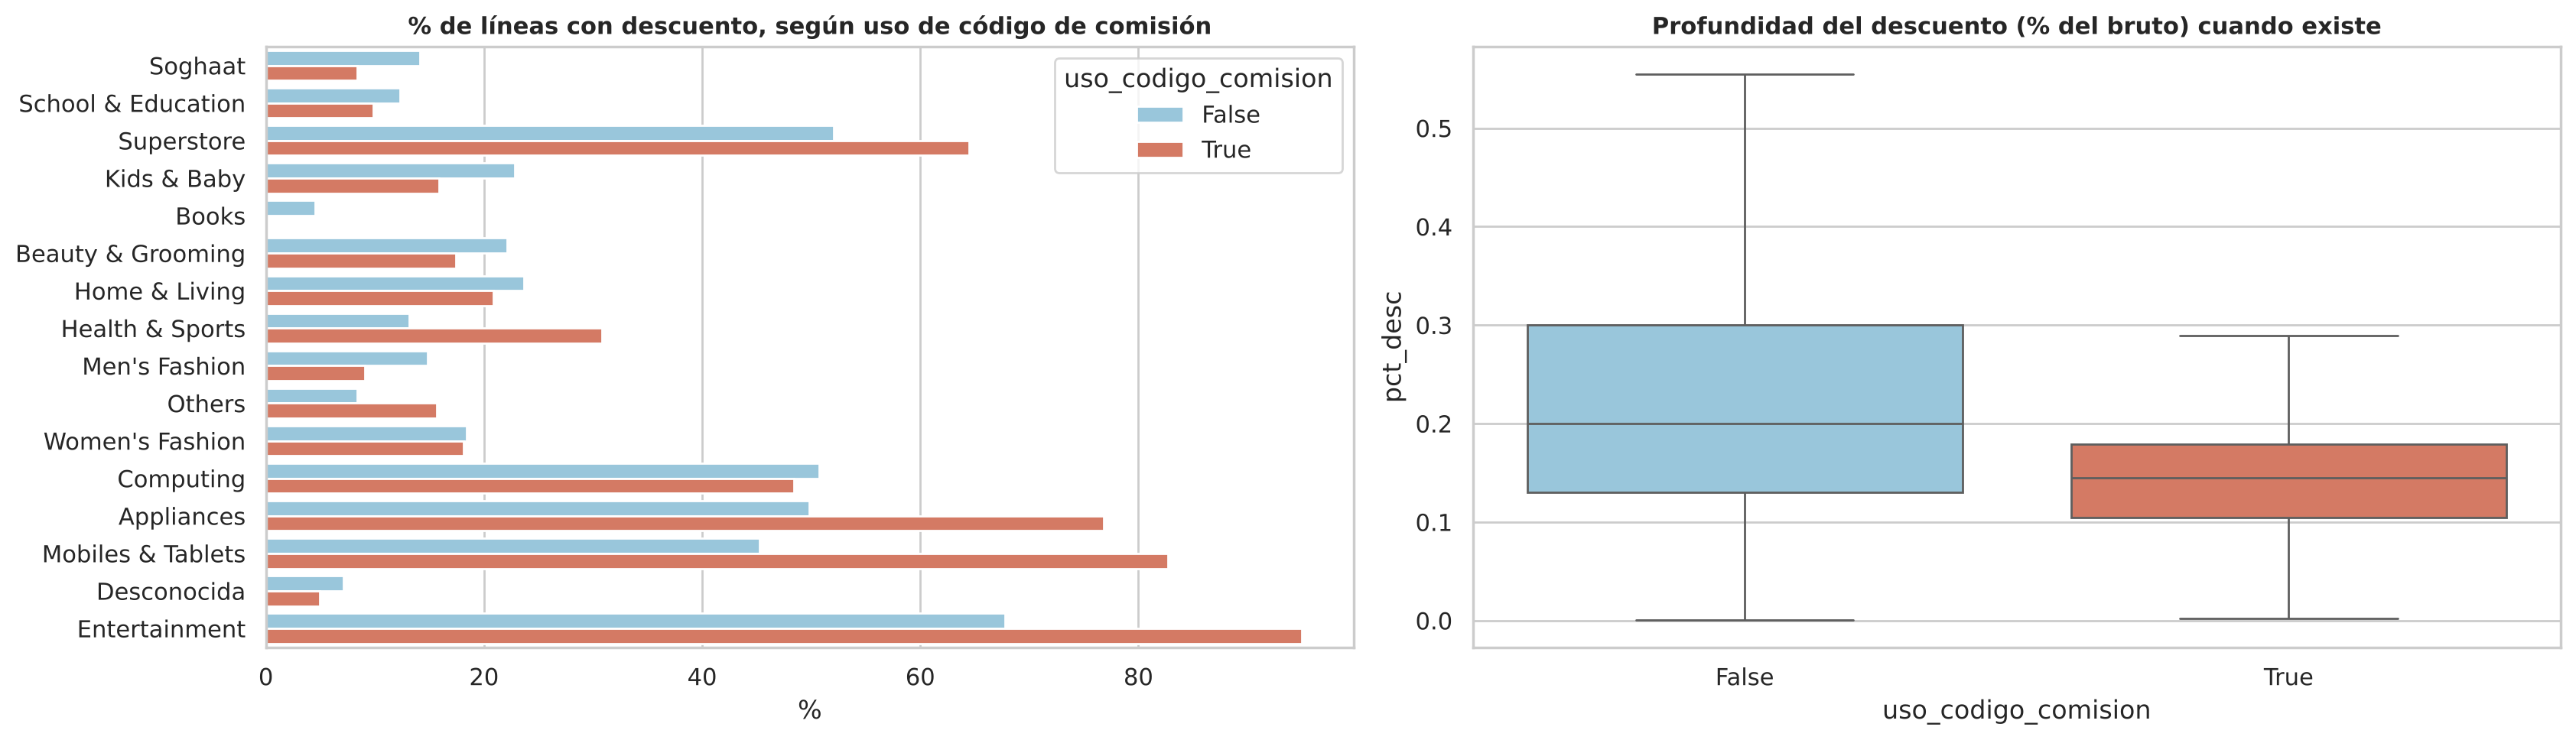

Mediana de profundidad del descuento: {False: 0.2, True: 0.145}
% de líneas con descuento (top 6 categorías): {'Entertainment': 78.0, 'Appliances': 55.0, 'Mobiles & Tablets': 54.0, 'Superstore': 54.0, 'Computing': 51.0, 'Home & Living': 24.0}


In [ ]:
v["con_descuento"] = v.discount_amount > 0
v["pct_desc"] = np.where(v.monto_bruto > 0, v.discount_amount / v.monto_bruto, np.nan)
ok = v[~v.descuento_inconsistente & (v.pct_desc > 0)]
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
tb = v.groupby(["category_name_1", "uso_codigo_comision"]).con_descuento.mean().mul(100).reset_index()
sns.barplot(data=tb, y="category_name_1", x="con_descuento", hue="uso_codigo_comision", order=orden, palette=["#8ecae6", "#e76f51"], ax=ax[0])
ax[0].set(title="% de líneas con descuento, según uso de código de comisión", ylabel="", xlabel="%")
sns.boxplot(data=ok, x="uso_codigo_comision", y="pct_desc", showfliers=False, palette=["#8ecae6", "#e76f51"], ax=ax[1])
ax[1].set(title="Profundidad del descuento (% del bruto) cuando existe")
plt.tight_layout(); plt.show()
print("Mediana de profundidad del descuento:", ok.groupby("uso_codigo_comision").pct_desc.median().round(3).to_dict())
print("% de líneas con descuento (top 6 categorías):", (v.groupby("category_name_1").con_descuento.mean() * 100).round(0).nlargest(6).to_dict())

**Lectura:** el descuento es habitual en *Entertainment* (78 % de las líneas), *Appliances* (55 %), *Superstore* (54 %), *Mobiles* (54 %) y *Computing* (51 %); en el resto no pasa del 24 %. Con código de comisión el descuento es **menos profundo** (mediana de 14,5 % del bruto contra 20 %), o sea que no funciona como descuento extra. Conviene tratarlo como contexto promocional y no como señal de preferencia.

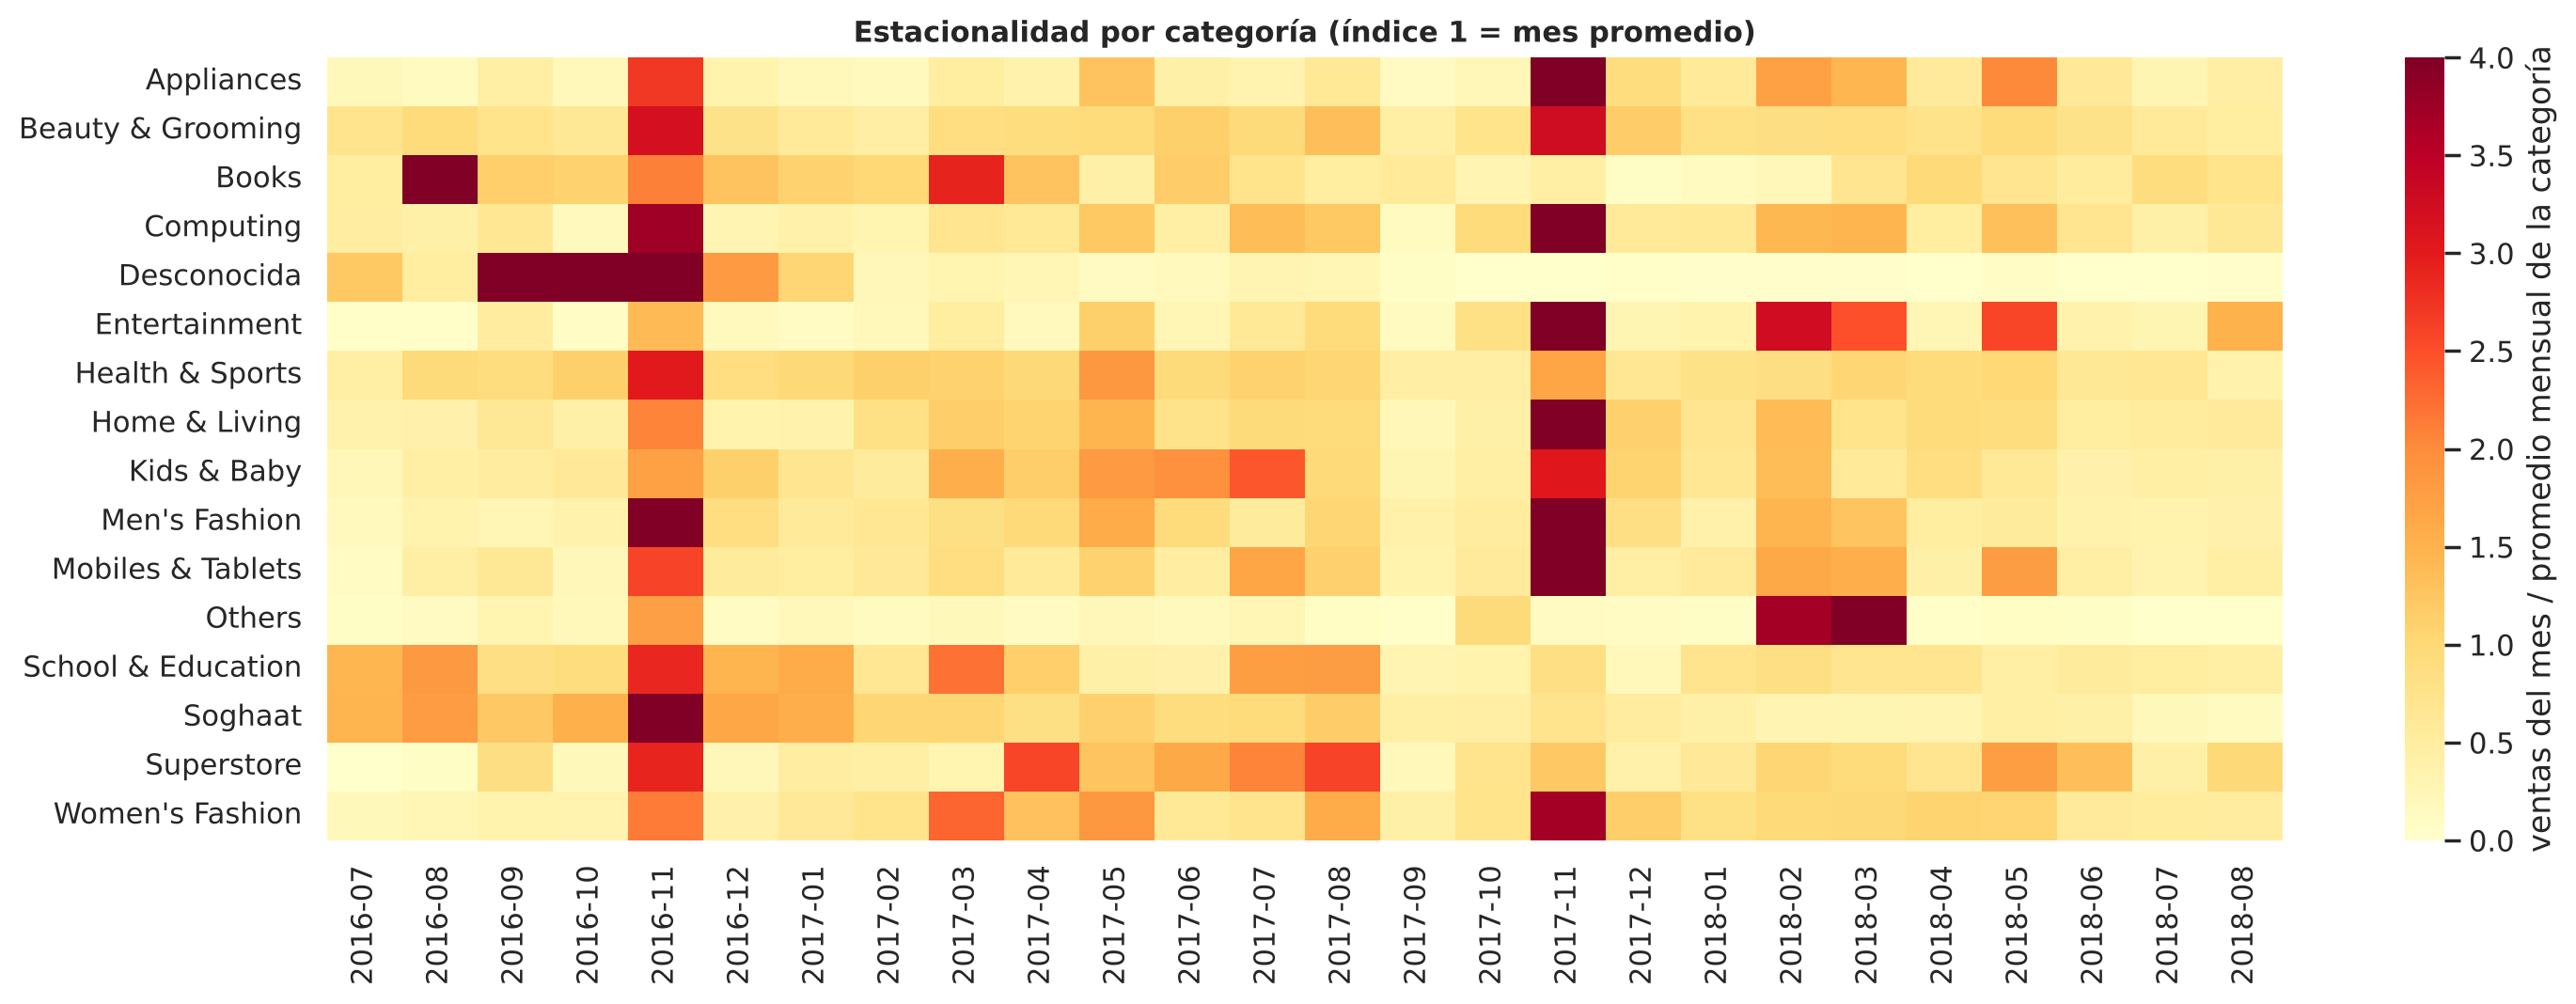

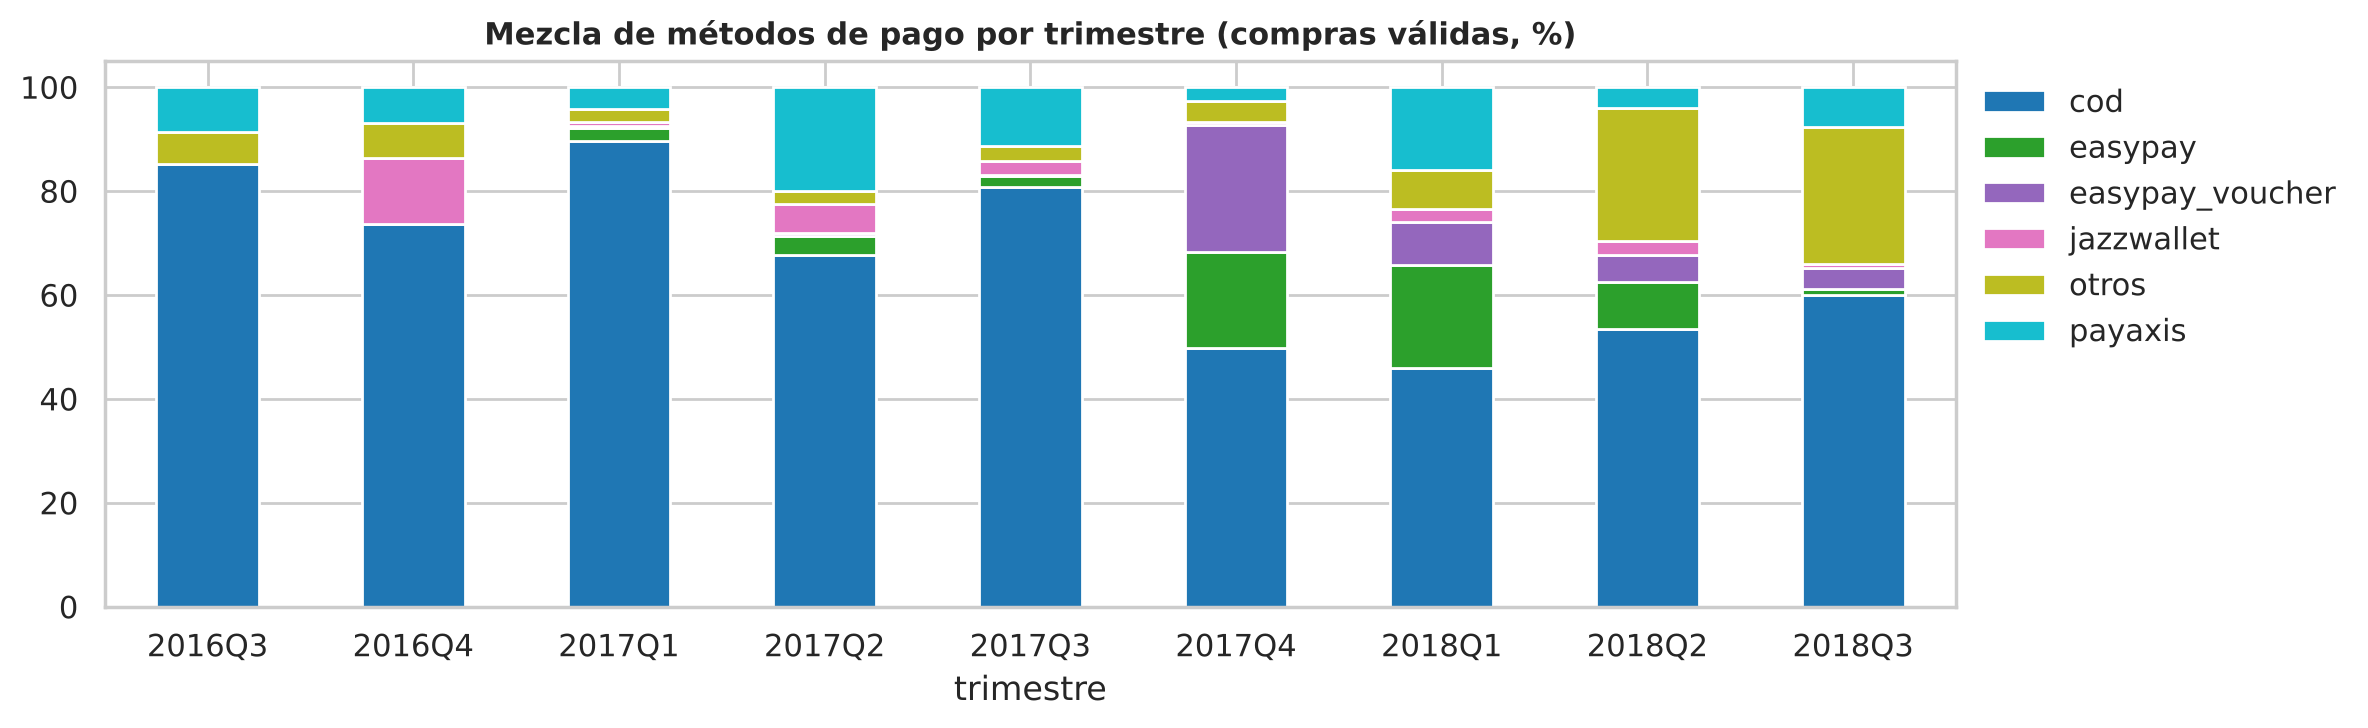

'Desconocida': 88% de sus líneas válidas son de 2016 · % de pagos cod por trimestre: {'2016Q3': 85.0, '2016Q4': 74.0, '2017Q1': 90.0, '2017Q2': 68.0, '2017Q3': 81.0, '2017Q4': 50.0, '2018Q1': 46.0, '2018Q2': 54.0, '2018Q3': 60.0}


In [ ]:
t = v.pivot_table(index="category_name_1", columns="anio_mes", values="item_id", aggfunc="size", fill_value=0)
plt.figure(figsize=(15, 5.5))
sns.heatmap(t.div(t.mean(axis=1), axis=0), cmap="YlOrRd", vmin=0, vmax=4, cbar_kws={"label": "ventas del mes / promedio mensual de la categoría"})
plt.title("Estacionalidad por categoría (índice 1 = mes promedio)"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

v["trimestre"] = v.created_at.dt.to_period("Q").astype(str)
top5 = v.payment_method.value_counts().head(5).index
pm = pd.crosstab(v.trimestre, v.payment_method.where(v.payment_method.isin(top5), "otros"), normalize="index") * 100
pm.plot.bar(stacked=True, figsize=(12, 3.8), colormap="tab10", rot=0); plt.title("Mezcla de métodos de pago por trimestre (compras válidas, %)")
plt.legend(bbox_to_anchor=(1, 1), frameon=False); plt.tight_layout(); plt.show()

desc_2016 = (v[v.category_name_1 == "Desconocida"].created_at.dt.year == 2016).mean()
print(f"'Desconocida': {desc_2016:.0%} de sus líneas válidas son de 2016 · % de pagos cod por trimestre:", pm["cod"].round(0).to_dict())

**Lectura**
- Hay **estacionalidad por categoría**, no solo un pico general: noviembre arrastra casi todo (sobre todo moda, electrónica y *Soghaat*), *Superstore* tiene ciclo propio (abril y agosto de 2017) y *Others* se dispara en febrero y marzo de 2018.
- *Desconocida* se concentra en 2016 (88 % de sus líneas válidas): es un problema de datos de esa etapa, no un tipo de producto.
- La **mezcla de pagos cambia**: `cod` oscila entre 68 % y 90 % hasta 2017-T3 y cae al 46-60 % desde 2017-T4, cuando crecen easypay y easypay_voucher. Las variables basadas en el pago deben ser robustas a este cambio.

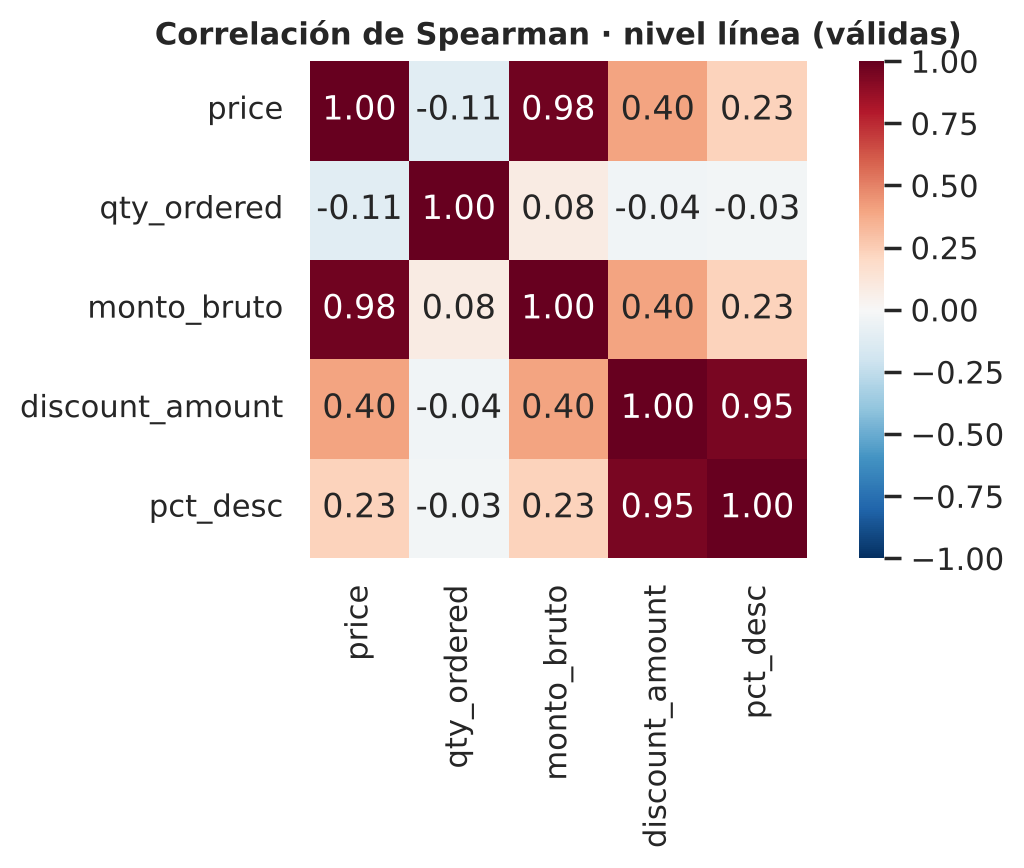

In [ ]:
corr = v[["price", "qty_ordered", "monto_bruto", "discount_amount", "pct_desc"]].astype(float).corr(method="spearman")
plt.figure(figsize=(6.5, 4.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Spearman · nivel línea (válidas)"); plt.tight_layout(); plt.show()

**Lectura:** `price` y `monto_bruto` casi coinciden (0,98) porque el 90 % de las líneas es de una unidad. La cantidad se relaciona levemente de forma **negativa** con el precio (−0,11): lo barato se compra en más unidades. `discount_amount` se mueve con `pct_desc` (0,95) y poco con el precio (0,23): el porcentaje es la versión comparable entre productos.

## 6. Análisis multivariado

Estructura conjunta de las variables por cliente y efecto combinado de categoría y método de pago.

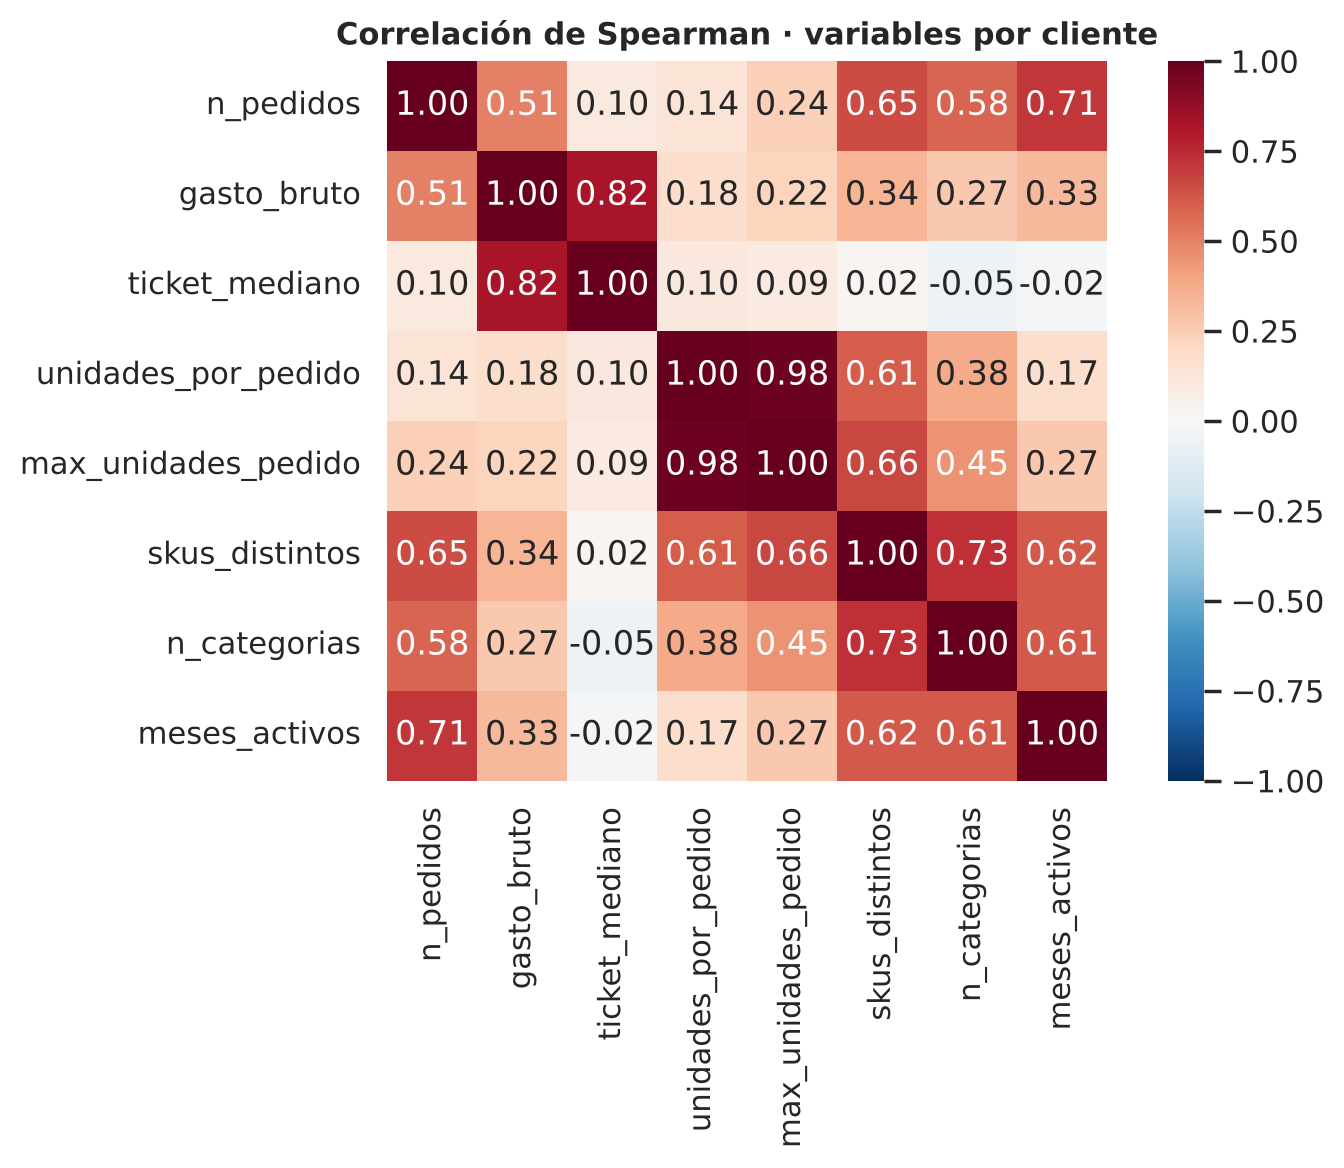

,PC1,PC2,PC3
n_pedidos,0.39,0.32,-0.23
gasto_bruto,0.27,0.49,0.38
ticket_mediano,0.07,0.44,0.60
unidades_por_pedido,0.28,-0.49,0.41
max_unidades_pedido,0.37,-0.42,0.31
skus_distintos,0.48,-0.11,-0.09
n_categorias,0.42,-0.03,-0.24
meses_activos,0.39,0.18,-0.34
% varianza,47.30,22.00,18.90


In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(np.log1p(cli[FEATS_PCA]).corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Spearman · variables por cliente"); plt.tight_layout(); plt.show()

Xpca = StandardScaler().fit_transform(np.log1p(cli[FEATS_PCA]))
pca = PCA(random_state=SEED).fit(Xpca)
carga = pd.DataFrame(pca.components_[:3].T, index=FEATS_PCA, columns=["PC1", "PC2", "PC3"]).round(2)
carga.loc["% varianza"] = (pca.explained_variance_ratio_[:3] * 100).round(1)
carga

**Lectura**
- Las variables de actividad se correlacionan entre sí (SKUs y categorías 0,73; pedidos y meses activos 0,71; SKUs y pedidos 0,65): describen un mismo eje de intensidad. `unidades_por_pedido` y `max_unidades_pedido` son casi redundantes (0,98).
- El **ticket mediano no se correlaciona con la actividad** (0,10 con pedidos, 0,02 con SKUs, −0,05 con categorías): comprar caro y comprar mucho son cosas distintas.
- PCA: **PC1 (47 %) = intensidad y variedad**, **PC2 (22 %)** opone valor (gasto, ticket) a cantidad (unidades por pedido) y **PC3 (19 %)** captura el tamaño del pedido.

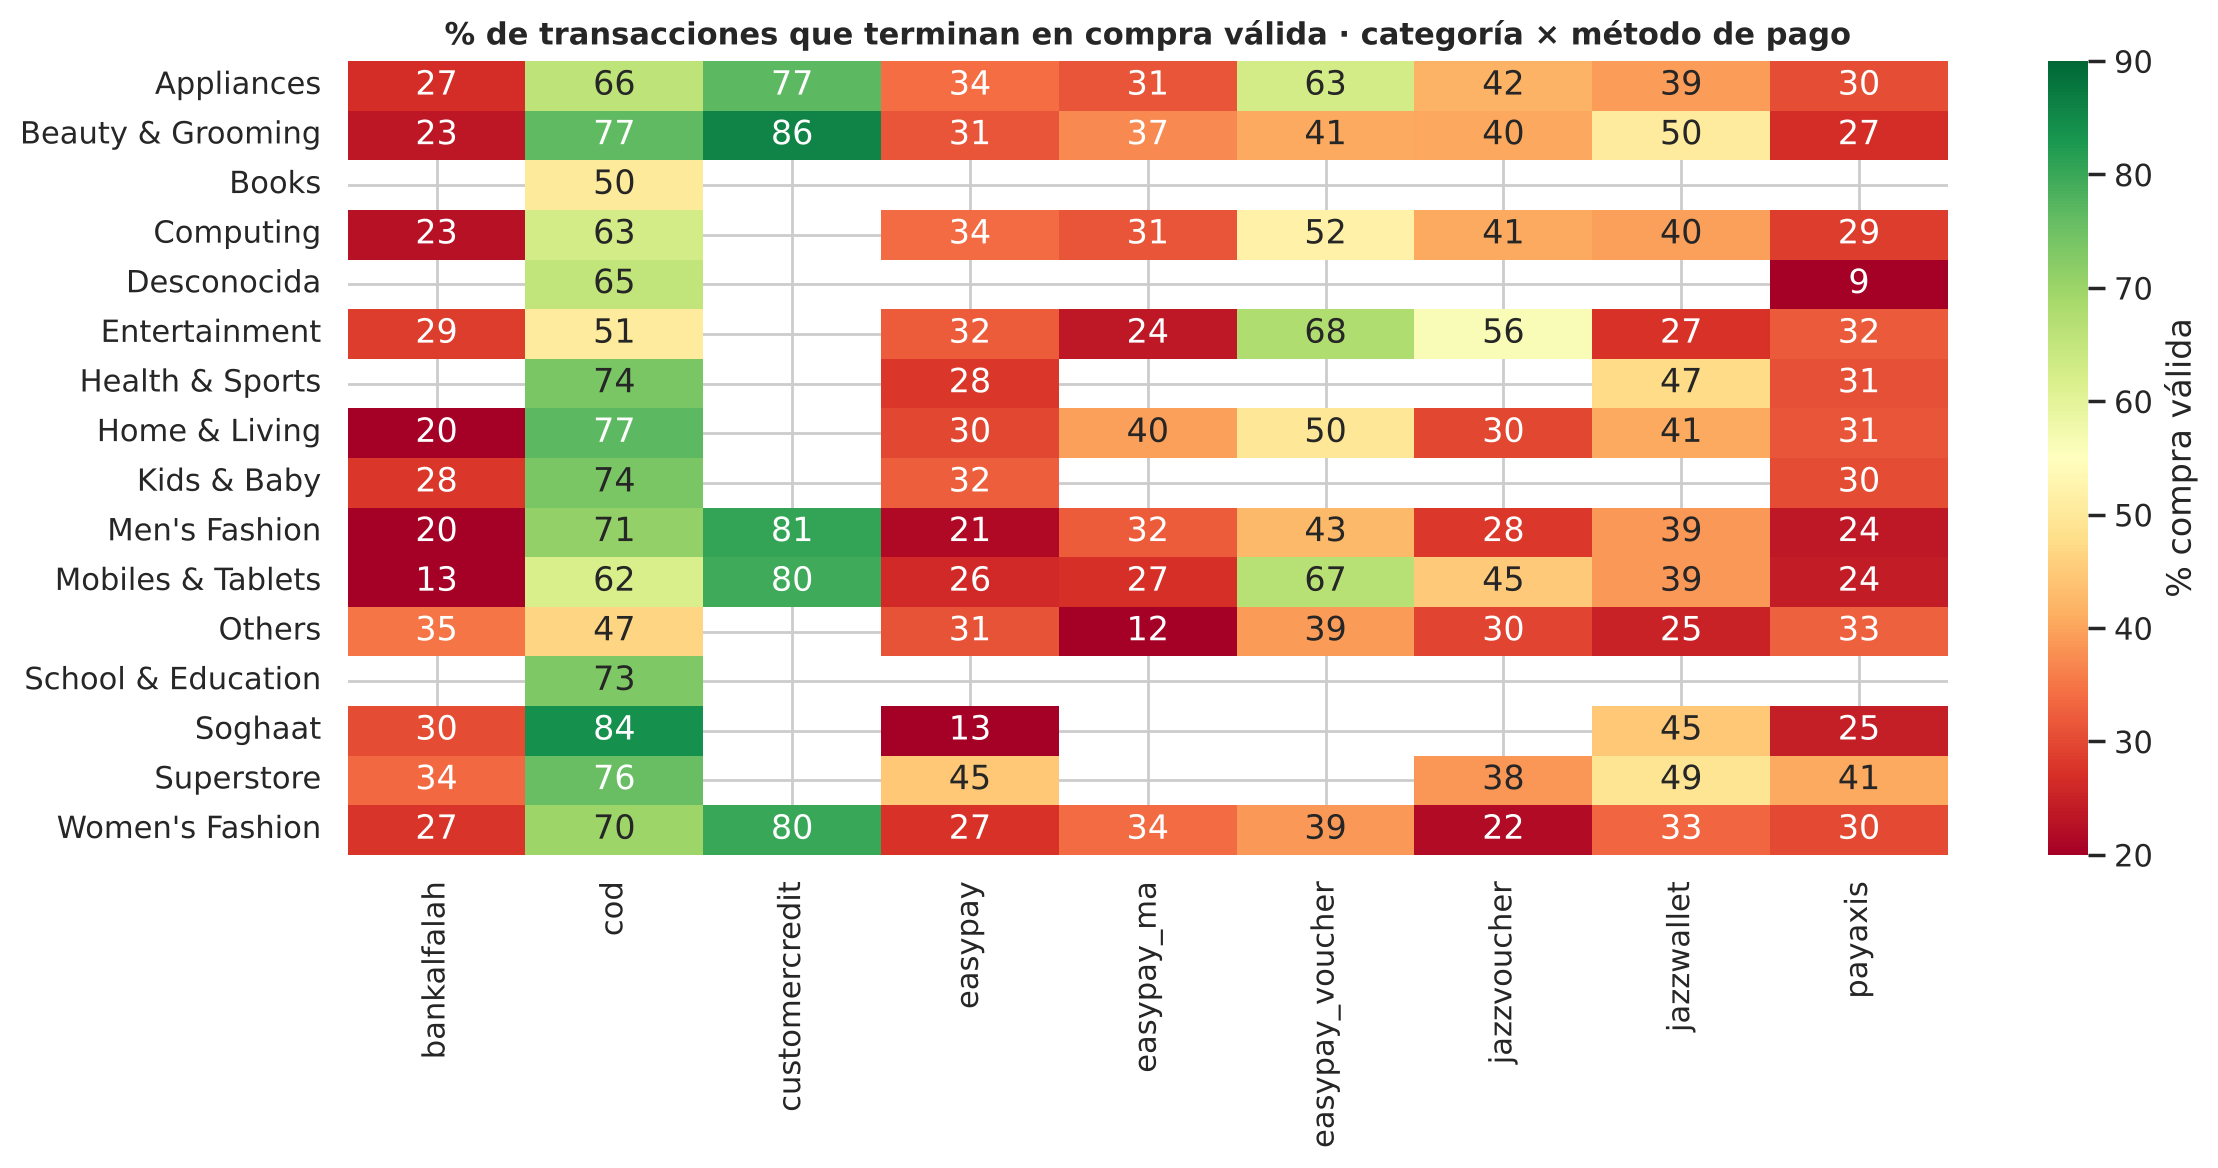

In [ ]:
# Tasa de compra válida por categoría × método de pago (métodos con >= 2.000 líneas; celdas con >= 300)
cnt = df.payment_method.value_counts()
sub = df[df.payment_method.isin(cnt[cnt >= 2000].index)]
tv = sub.pivot_table(index="category_name_1", columns="payment_method", values="es_compra_valida", aggfunc="mean") * 100
n = sub.pivot_table(index="category_name_1", columns="payment_method", values="item_id", aggfunc="size")
plt.figure(figsize=(12, 6)); sns.heatmap(tv.where(n >= 300), annot=True, fmt=".0f", cmap="RdYlGn", vmin=20, vmax=90, cbar_kws={"label": "% compra válida"})
plt.title("% de transacciones que terminan en compra válida · categoría × método de pago"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

**Lectura:** el efecto del método de pago es **transversal a las categorías**: `cod` y crédito del cliente concretan bien en casi todas; bankalfalah y payaxis, poco. La excepción es `easypay_voucher`, que funciona bien en electrónica (*Entertainment* 68 %, *Mobiles* 67 %, *Appliances* 63 %), muy por encima del 28-29 % de easypay y payaxis. Es fricción de pago, no preferencia.

## 7. Segmentación de clientes por perfil

A partir de los hallazgos del EDA se crea la columna categórica **`perfil_cliente`**, según los **pedidos válidos** (`n_pedidos`):

| Perfil | Regla | Rol para el recomendador |
|---|---|---|
| **Bajo perfil** | 1 pedido válido | Poco interés: no hay recurrencia que fidelizar. |
| **Perfil intermedio** | 2 a 4 pedidos válidos | **Target**: ya repitieron, son quienes el sistema debe empujar. |
| **Alto perfil** | 5 o más pedidos válidos | **Meta**: que los intermedios lleguen acá. |

Se cuentan pedidos y no SKUs porque miden recurrencia, que es lo que el negocio quiere aumentar, y no dependen de cuántos productos entran en un pedido. La variedad de SKUs queda aparte (`nivel_historial_skus`) para el cold start. Primero se verifica si los cortes tienen sentido:

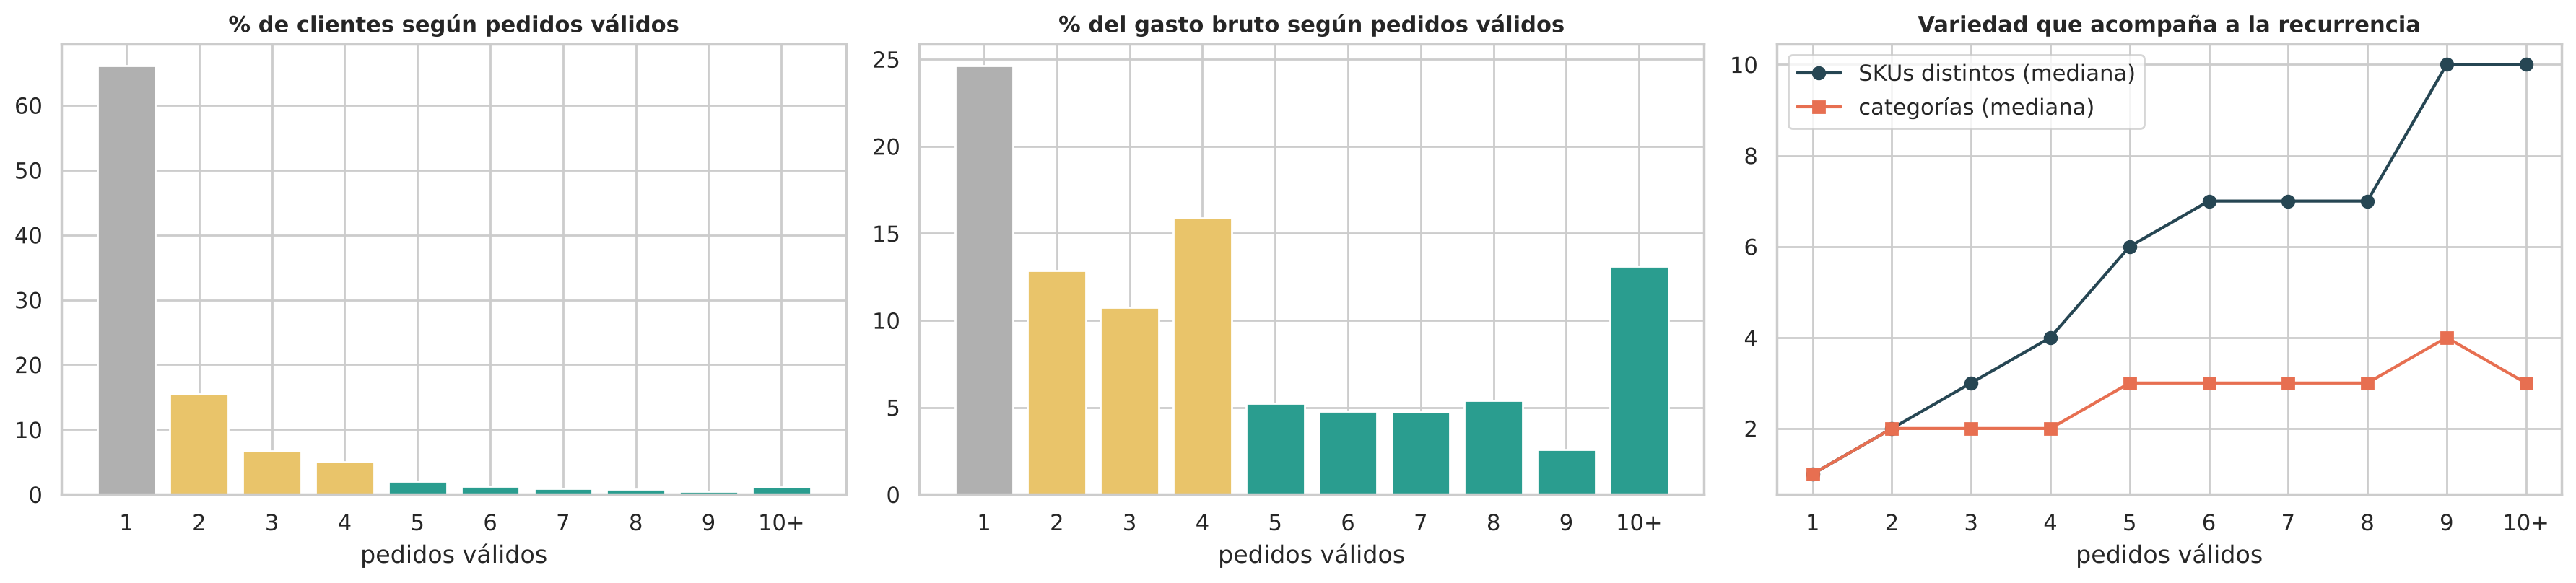

,clientes,% clientes,% gasto,skus,cats,meses,ticket
n,,,,,,,
1,51662,66.1,24.6,1.0,1.0,1.0,1299.0
2,12097,15.5,12.9,2.0,2.0,1.0,1582.9
3,5243,6.7,10.8,3.0,2.0,2.0,1499.0
4,3918,5.0,15.9,4.0,2.0,1.0,3504.0
5,1574,2.0,5.2,6.0,3.0,3.0,1419.0
6,999,1.3,4.8,7.0,3.0,3.0,1688.5
7,740,0.9,4.7,7.0,3.0,3.0,1771.1
8,612,0.8,5.4,7.0,3.0,3.0,3029.8
9,388,0.5,2.6,10.0,4.0,4.0,1550.4


In [ ]:
t = (cli.assign(n=cli.n_pedidos.clip(upper=10)).groupby("n")
        .agg(clientes=("gasto_bruto", "size"), gasto=("gasto_bruto", "sum"), skus=("skus_distintos", "median"),
             cats=("n_categorias", "median"), meses=("meses_activos", "median"), ticket=("ticket_mediano", "median")))
t["% clientes"] = t.clientes / t.clientes.sum() * 100
t["% gasto"] = t.gasto / t.gasto.sum() * 100
colores = [COL_PERFIL[ORDEN_PERFIL[0]]] + [COL_PERFIL[ORDEN_PERFIL[1]]] * 3 + [COL_PERFIL[ORDEN_PERFIL[2]]] * 6
etq = [str(i) for i in t.index]; etq[-1] += "+"

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
for a, col, tit in [(ax[0], "% clientes", "% de clientes según pedidos válidos"), (ax[1], "% gasto", "% del gasto bruto según pedidos válidos")]:
    a.bar(etq, t[col], color=colores); a.set(title=tit, xlabel="pedidos válidos")
ax[2].plot(etq, t.skus, marker="o", label="SKUs distintos (mediana)", color=AZUL); ax[2].plot(etq, t.cats, marker="s", label="categorías (mediana)", color="#e76f51")
ax[2].set(title="Variedad que acompaña a la recurrencia", xlabel="pedidos válidos"); ax[2].legend()
plt.tight_layout(); plt.show()
t[["clientes", "% clientes", "% gasto", "skus", "cats", "meses", "ticket"]].round(1)

**Lectura:** los cortes tienen respaldo empírico.
- Pasar de 4 a 5 pedidos coincide con un **salto de variedad**: la mediana de SKUs sube de 4 a 6, la de categorías de 2 a 3 y la de meses activos de 1 a 3.
- Entre 1 y 2 pedidos también cambia el tipo de cliente: quien repite ya tiene 2 SKUs y 2 categorías de mediana, contra 1 y 1.
- La base está muy desbalanceada: el 66 % tiene 1 pedido y solo el 6,7 % llega a 5 o más.

,clientes,% clientes,% pedidos,% gasto,pedidos_med,unidades_med,gasto_med,ticket_med,skus_med,cats_med,meses_med
perfil_cliente,,,,,,,,,,,
Bajo perfil,51662,66.1,35.1,24.6,1.0,1.0,1400.0,1299.0,1.0,1.0,1.0
Perfil intermedio,21258,27.2,37.7,39.5,2.0,4.0,5491.8,1716.8,3.0,2.0,2.0
Alto perfil,5202,6.7,27.2,35.9,7.0,10.0,23850.0,1737.5,7.0,3.0,3.0


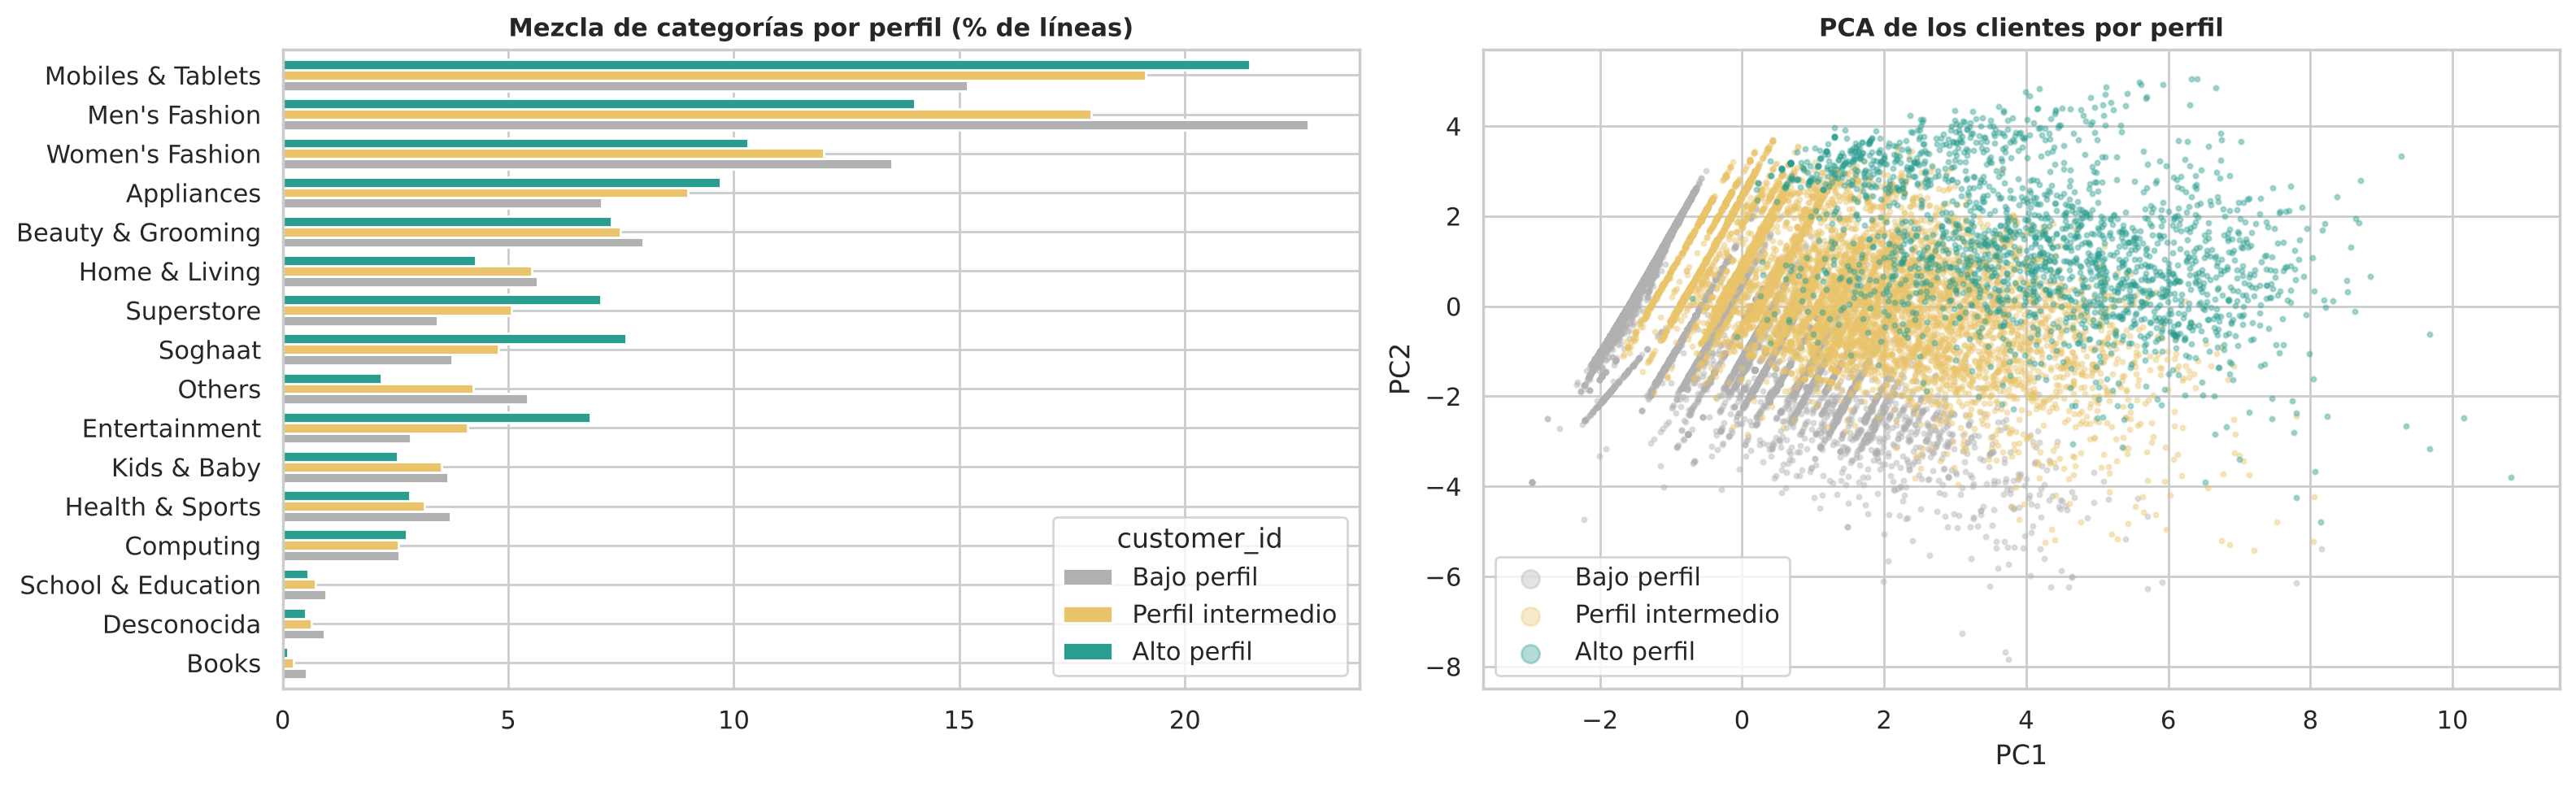

In [ ]:
cli["perfil_cliente"] = pd.cut(cli.n_pedidos, [0, 1, 4, np.inf], labels=ORDEN_PERFIL).astype(CategoricalDtype(ORDEN_PERFIL, ordered=True))

res = cli.groupby("perfil_cliente", observed=True).agg(
    clientes=("gasto_bruto", "size"), pedidos=("n_pedidos", "sum"), gasto=("gasto_bruto", "sum"),
    pedidos_med=("n_pedidos", "median"), unidades_med=("unidades", "median"), gasto_med=("gasto_bruto", "median"), ticket_med=("ticket_mediano", "median"),
    skus_med=("skus_distintos", "median"), cats_med=("n_categorias", "median"), meses_med=("meses_activos", "median"))
for i, col in enumerate(("clientes", "pedidos", "gasto"), start=1):
    res.insert(i, f"% {col}", res[col] / res[col].sum() * 100)
display(res.drop(columns=["pedidos", "gasto"]).round(1))

mix = (pd.crosstab(v.category_name_1, v.customer_id.map(cli.perfil_cliente), normalize="columns")[ORDEN_PERFIL] * 100).sort_values("Perfil intermedio")
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
mix.plot.barh(ax=ax[0], color=list(COL_PERFIL.values()), width=0.8); ax[0].set(title="Mezcla de categorías por perfil (% de líneas)", ylabel="")
pca_scatter(ax[1], Xpca, cli.perfil_cliente.values, COL_PERFIL, 30000, "PCA de los clientes por perfil")
plt.tight_layout(); plt.show()

**Lectura**
- **Bajo perfil:** 51.662 clientes (66,1 %) con solo el 24,6 % del gasto.
- **Perfil intermedio (target):** 21.258 clientes (27,2 %) con el **39,5 % del gasto** y el 37,7 % de los pedidos: el grupo que más gasta en total y con mayor margen de crecimiento.
- **Alto perfil (meta):** 5.202 clientes (6,7 %) con el 35,9 % del gasto. Gastan **4,3 veces más** que un intermedio (mediana PKR 23.850 contra 5.492), con 7 pedidos contra 2 y 7 SKUs contra 3.
- **El ticket mediano es casi el mismo** (PKR 1.717 contra 1.738): el alto perfil gasta más porque **compra más veces**, no porque compre más caro. El objetivo del recomendador es generar *más pedidos*.
- **Categorías:** el alto perfil sobrerrepresenta *Superstore*, *Soghaat* y *Entertainment* (aprox. 7-8 % de sus líneas contra 3-4 % en bajo perfil); *Men's Fashion* concentra la compra única (23 % de las líneas del bajo perfil contra 14 % del alto).
- **PCA:** los perfiles forman un **continuo** con superposición, no clusters. Los cortes son una decisión de negocio, razonable pero no natural.

In [ ]:
# ¿Cuántos intermedios llegan a Alto perfil? Corte al 2018-02-28 y se observa el resultado ~6 meses después
CORTE_T = pd.Timestamp("2018-02-28")
perfil_de = lambda n: pd.cut(n, [0, 1, 4, np.inf], labels=ORDEN_PERFIL)
n_t = ped[ped.fecha <= CORTE_T].groupby("customer_id").size()
n_fin = ped.groupby("customer_id").size().reindex(n_t.index)
trans = pd.crosstab(perfil_de(n_t).rename("perfil al corte"), perfil_de(n_fin).rename("perfil al final"), normalize="index") * 100
display(trans.round(1).loc[ORDEN_PERFIL, ORDEN_PERFIL])
print(f"Clientes en el corte: {len(n_t):,} · ventana de observación: {CORTE_T + pd.Timedelta(days=1):%Y-%m-%d} → {df.created_at.max():%Y-%m-%d}")

ids_int = n_t.index[n_t.between(2, 4)]
vt = v[(v.created_at <= CORTE_T) & v.customer_id.isin(ids_int)]; gt = vt.groupby("customer_id")
ft = pd.DataFrame({"pedidos": n_t.reindex(ids_int), "skus": gt.sku.nunique(), "categorias": gt.category_name_1.nunique(),
                   "gasto_bruto": gt.monto_bruto.sum(), "unid_por_pedido": gt.qty_ordered.sum() / n_t.reindex(ids_int),
                   "pct_cod": vt.assign(c=vt.payment_method == "cod").groupby("customer_id").c.mean() * 100,
                   "recencia_dias": (CORTE_T - gt.created_at.max()).dt.days,
                   "antiguedad_dias": (CORTE_T - gt.customer_since.first()).dt.days})
ft["convierte"] = n_fin.reindex(ids_int) >= 5
print(f"\nIntermedios al corte: {len(ft):,} · pasaron a Alto perfil al final: {ft.convierte.sum():,} ({ft.convierte.mean():.1%})")
display(ft.groupby("convierte").median().T.rename(columns={False: "no convierte", True: "convierte"}).round(1))

bk = pd.cut(ft.recencia_dias, [-1, 30, 90, 180, np.inf], labels=["≤30 días", "31-90 días", "91-180 días", ">180 días"])
rr = ft.groupby(bk, observed=True).convierte.agg(clientes="size", convierten="sum", tasa="mean"); rr["tasa"] *= 100
print("Conversión según recencia al corte:"); display(rr.round(1))
tasa_conv = lambda g: (ft.groupby(g).convierte.mean() * 100).round(1).to_dict()
print("Conversión según pedidos al corte:", tasa_conv(ft.pedidos))
print("Conversión según categorías distintas (1, 2, 3+):", tasa_conv(ft.categorias.clip(upper=3)))
print("Conversión según SKUs distintos (2, 3, 4, 5+):", tasa_conv(ft.skus.clip(lower=2, upper=5)))

perfil al final,Bajo perfil,Perfil intermedio,Alto perfil
perfil al corte,,,
Bajo perfil,96.4,3.4,0.2
Perfil intermedio,0.0,96.1,3.9
Alto perfil,0.0,0.0,100.0


Clientes en el corte: 63,871 · ventana de observación: 2018-03-01 → 2018-08-28

Intermedios al corte: 17,124 · pasaron a Alto perfil al final: 668 (3.9%)


convierte,no convierte,convierte
pedidos,2.0,4.0
skus,3.0,3.0
categorias,2.0,2.0
gasto_bruto,4598.5,22220.0
unid_por_pedido,1.2,1.2
pct_cod,100.0,16.7
recencia_dias,199.0,81.5
antiguedad_dias,333.0,119.0


Conversión según recencia al corte:


,clientes,convierten,tasa
recencia_dias,,,
≤30 días,1575,240,15.2
31-90 días,1622,116,7.2
91-180 días,5054,201,4.0
>180 días,8873,111,1.3


Conversión según pedidos al corte: {2: 1.4, 3: 4.5, 4: 11.0}
Conversión según categorías distintas (1, 2, 3+): {1: 4.0, 2: 2.7, 3: 5.7}
Conversión según SKUs distintos (2, 3, 4, 5+): {2: 3.1, 3: 3.2, 4: 4.4, 5: 5.9}


**¿Cuántos intermedios llegan a alto perfil sin recomendador?** Corte al 2018-02-28 y resultado unos 6 meses después.
- De 17.124 intermedios solo **668 (3,9 %)** llegaron a alto perfil. Esa es la **línea de base natural** contra la que medir al recomendador.
- La conversión sube con la cercanía: 1,4 % con 2 pedidos, 4,5 % con 3 y **11 % con 4**.
- **La recencia es la señal más fuerte:** convierte el 15,2 % de los que compraron en los últimos 30 días y solo el 1,3 % de los que llevan más de 180 días sin comprar, que son más de la mitad de los intermedios (8.873 de 17.124). El recomendador rinde sobre clientes **activos**; a los dormidos les corresponde una acción de reactivación.
- Los que convierten ya gastaban más (mediana PKR 22.220 contra 4.598), son más nuevos (119 contra 333 días de antigüedad) y pagan menos contra entrega. Es en buena parte un **efecto cohorte** (captados cuando el pago online pesaba más y todavía activos), no una relación causal.
- La variedad ayuda poco por sí sola: 3,1 % con 2 SKUs distintos contra 5,9 % con 5 o más.

## 8. Variables derivadas para el recomendador

Tres tablas, una por entidad (todas sin distribuidores):

| Tabla | Grano | Para qué |
|---|---|---|
| `interacciones` | cliente × SKU | Feedback implícito para filtrado colaborativo |
| `items_features` | SKU | Contenido, popularidad, calidad y vigencia |
| `clientes_features` | cliente | Perfil, RFM, `perfil_cliente` y cold start |

**Decisiones de diseño**
- Feedback **implícito** (compró): `log1p(unidades)` amortigua las compras de varias unidades y `recompra` marca la repetición.
- `peso_temporal = exp(−días / 90)` da más peso a lo reciente; la fecha de corte es el día posterior a la última compra del dataset.
- Las tasas de cancelación y reembolso usan **todas** las transacciones y se **suavizan** con un prior bayesiano (a=10).
- `pedidos_para_alto_perfil` mide la distancia de cada cliente a la meta.

In [ ]:
CORTE = v.created_at.max() + pd.Timedelta(days=1)       # fecha de referencia para recencias
TAU = 90                                                 # vida media (días) del peso temporal

# 8.1 Interacciones cliente × SKU (feedback implícito)
inter = (v.groupby(["customer_id", "sku"])
           .agg(n_compras=("increment_id", "nunique"), unidades=("qty_ordered", "sum"), monto_bruto=("monto_bruto", "sum"),
                primera_compra=("created_at", "min"), ultima_compra=("created_at", "max")).reset_index())
cat_sku = (v.groupby(["sku", "category_name_1"]).size().reset_index(name="n").sort_values(["sku", "n"], ascending=[True, False])
             .drop_duplicates("sku").set_index("sku").category_name_1)
inter["categoria"] = inter.sku.map(cat_sku)
inter["feedback_implicito"] = np.log1p(inter.unidades)                   # amortigua compras de varias unidades
inter["recompra"] = inter.n_compras > 1
inter["dias_desde_ultima"] = (CORTE - inter.ultima_compra).dt.days
inter["peso_temporal"] = np.exp(-inter.dias_desde_ultima / TAU)
inter["perfil_cliente"] = inter.customer_id.map(cli.perfil_cliente)
print(f"Interacciones únicas cliente×SKU: {len(inter):,} (líneas válidas: {len(v):,})")
print(f"Recompra (mismo cliente y SKU, >1 pedido): {inter.recompra.mean():.1%} · por perfil:", (inter.groupby("perfil_cliente", observed=True).recompra.mean() * 100).round(1).to_dict())
inter.head(3)

Interacciones únicas cliente×SKU: 190,129 (líneas válidas: 213,768)
Recompra (mismo cliente y SKU, >1 pedido): 7.2% · por perfil: {'Bajo perfil': 0.0, 'Perfil intermedio': 9.9, 'Alto perfil': 15.1}


,customer_id,sku,n_compras,unidades,monto_bruto,primera_compra,ultima_compra,categoria,feedback_implicito,recompra,dias_desde_ultima,peso_temporal,perfil_cliente
0,1,kreations_YI 06-L,1,1,1950.0,2016-07-01,2016-07-01,Women's Fashion,0.693147,False,789,0.000156,Bajo perfil
1,3,ALHAMRA_US-0961-K,1,1,299.0,2017-05-19,2017-05-19,Men's Fashion,0.693147,False,467,0.005578,Bajo perfil
2,3,BD_BIG DEAL_16,1,1,350.0,2017-05-19,2017-05-19,Mobiles & Tablets,0.693147,False,467,0.005578,Bajo perfil


**Lectura:** 213.768 líneas se resumen en **190.129 pares cliente×SKU**. La recompra del mismo SKU es baja (7,2 %) y crece con el perfil: 9,9 % en intermedios y 15,1 % en alto perfil (0 en bajo perfil por definición). Predomina el descubrimiento.

In [ ]:
# 8.2 Features de producto
tasa_sku = pd.crosstab(df.sku, df.grupo_status)
prior_c = (df.grupo_status == "cancelada").mean()
prior_r = (df.grupo_status == "reembolso").sum() / (df.es_compra_valida.sum() + (df.grupo_status == "reembolso").sum())
A = 10                                                    # suavizado bayesiano

inter["es_alto"] = inter.perfil_cliente == "Alto perfil"
inter["es_interm"] = inter.perfil_cliente == "Perfil intermedio"
gi = inter.groupby("sku")
items = pd.DataFrame({
    "categoria": cat_sku, "n_clientes": gi.size(), "n_lineas": v.groupby("sku").size(), "unidades": gi.unidades.sum(),
    "precio_mediano": v.groupby("sku").price.median(), "primera_venta": v.groupby("sku").created_at.min(), "ultima_venta": v.groupby("sku").created_at.max(),
    "tasa_recompra": gi.recompra.mean(), "pct_compradores_alto_perfil": gi.es_alto.mean() * 100, "pct_compradores_intermedios": gi.es_interm.mean() * 100})
items["popularidad_log"] = np.log1p(items.n_clientes)
items["rank_popularidad"] = items.n_clientes.rank(ascending=False, method="first").astype(int)
items["pct_precio_en_categoria"] = items.groupby("categoria").precio_mediano.rank(pct=True)
items["nivel_precio"] = pd.cut(items.pct_precio_en_categoria, [0, 1/3, 2/3, 1], labels=["económico", "medio", "premium"])
items["dias_desde_ultima_venta"] = (CORTE - items.ultima_venta).dt.days
items["vida_dias"] = (items.ultima_venta - items.primera_venta).dt.days
items["activo_90d"] = items.dias_desde_ultima_venta <= 90
items["item_frio"] = items.n_clientes < 5
ts = tasa_sku.reindex(items.index)
items["tasa_cancelacion_suav"] = (ts.cancelada + A * prior_c) / (ts.sum(axis=1) + A)
items["tasa_reembolso_suav"] = (ts.reembolso + A * prior_r) / (ts.reembolso + ts["válida"] + A)
print(f"SKUs: {len(items):,} · fríos (<5 clientes): {items.item_frio.mean():.1%} · activos en 90 días: {items.activo_90d.mean():.1%} · vida mediana: {items.vida_dias.median():.0f} días · vendidos en un solo día: {(items.vida_dias == 0).mean():.1%}")
items.describe().T.round(2)[["mean", "50%", "max"]]

SKUs: 53,638 · fríos (<5 clientes): 86.7% · activos en 90 días: 12.6% · vida mediana: 0 días · vendidos en un solo día: 59.9%


,mean,50%,max
n_clientes,3.54467,1.0,815.0
n_lineas,3.985383,1.0,2607.0
unidades,4.741284,1.0,2611.0
precio_mediano,2495.88629,840.0,189691.0
primera_venta,2017-08-29 11:58:05.633320,2017-10-10 00:00:00,2018-08-28 00:00:00
ultima_venta,2017-09-29 14:05:51.422498,2017-10-29 00:00:00,2018-08-28 00:00:00
tasa_recompra,0.028276,0.0,1.0
pct_compradores_alto_perfil,21.261751,0.0,100.0
pct_compradores_intermedios,38.689236,28.571429,100.0
popularidad_log,1.081919,0.693147,6.704414


**Lectura:** el catálogo es **efímero y de cola muy larga**. El 86,7 % de los SKUs tiene menos de 5 compradores, la vida mediana de un SKU es de **0 días** (el 59,9 % se vende en un solo día) y solo el **12,6 %** vendió algo en los últimos 90 días. Por eso (a) el filtrado colaborativo puro sobre SKUs será frágil, (b) hay que **recomendar solo ítems activos** (`activo_90d`) y (c) conviene apoyarse en atributos que generalizan: categoría, nivel de precio y popularidad reciente.

In [ ]:
# 8.3 Features de cliente
cat_fav = (v.groupby(["customer_id", "category_name_1"]).size().reset_index(name="n").sort_values(["customer_id", "n"], ascending=[True, False])
             .drop_duplicates("customer_id").set_index("customer_id"))
share = pd.crosstab(v.customer_id, v.category_name_1, normalize="index")
share.columns = ["share_cat_" + "".join(ch if ch.isalnum() else "_" for ch in c.lower()).strip("_") for c in share.columns]
alta = v.groupby("customer_id").customer_since.first()

cf = cli[["perfil_cliente", "n_pedidos", "n_lineas", "unidades", "gasto_bruto", "ticket_mediano", "unidades_por_pedido", "max_unidades_pedido",
          "skus_distintos", "n_categorias", "meses_activos", "pedidos_por_mes_activo", "pct_cod", "pct_codigo_comision",
          "tasa_cancelacion", "tasa_reembolso", "n_senales_dist", "zona_gris", "cuenta_interna"]].copy()
cf["recencia_dias"] = (CORTE - cli.ultima_compra).dt.days
cf["antiguedad_dias"] = (CORTE - alta).dt.days
cf["dias_alta_a_primera_compra"] = (cli.primera_compra - alta).dt.days
cf["categoria_favorita"] = cat_fav.category_name_1
cf["concentracion_categoria_fav"] = cat_fav.n / cli.n_lineas
cf["entropia_categorias"] = -(share * np.log(share.where(share > 0, 1))).sum(axis=1)
cf["nivel_historial_skus"] = pd.cut(cli.skus_distintos, [0, 1, 4, np.inf], labels=["frío (1 SKU)", "tibio (2-4)", "cálido (5+)"])
cf["pedidos_para_alto_perfil"] = (5 - cf.n_pedidos).clip(lower=0)          # distancia a la meta
quintil = lambda s, asc: pd.qcut(s.rank(method="first", ascending=asc), 5, labels=[1, 2, 3, 4, 5]).astype(int)   # 5 = mejor
cf["R"], cf["F"], cf["M"] = quintil(cf.recencia_dias, False), quintil(cf.n_pedidos, True), quintil(cf.gasto_bruto, True)
cf["rfm_score"] = cf.R * 100 + cf.F * 10 + cf.M
cf = cf.join(share)
print(f"Clientes: {len(cf):,} · columnas: {cf.shape[1]}")
pd.crosstab(cf.perfil_cliente, cf.nivel_historial_skus)

Clientes: 78,122 · columnas: 47


nivel_historial_skus,frío (1 SKU),tibio (2-4),cálido (5+)
perfil_cliente,,,
Bajo perfil,39559,10770,1333
Perfil intermedio,3428,13257,4573
Alto perfil,104,1135,3963


**Lectura:** 47 columnas por cliente (16 son `share_cat_*`, el perfil de categorías). El **23 % de los clientes de bajo perfil** compró 2 o más SKUs en su único pedido, así que aportan señal de co-compra aunque no repitan. Entre los intermedios, 3.428 (16 %) siguen fríos en SKUs y 4.573 (22 %) ya son cálidos: sirve para elegir estrategia (popularidad y contenido para fríos, filtrado colaborativo para cálidos).

Matriz cliente×SKU: 78,122 × 53,638 · densidad 0.0045% | cliente×categoría: 9.1%
SKUs para cubrir el 50 % / 80 % de las interacciones: 3,101 (5.8%) / 18,671 (34.8%)
SKUs con >= 5 clientes: 13.3% · con 1 solo cliente: 59.5%
Clientes con >= 2 SKUs distintos: 44.8% · >= 5: 12.6%


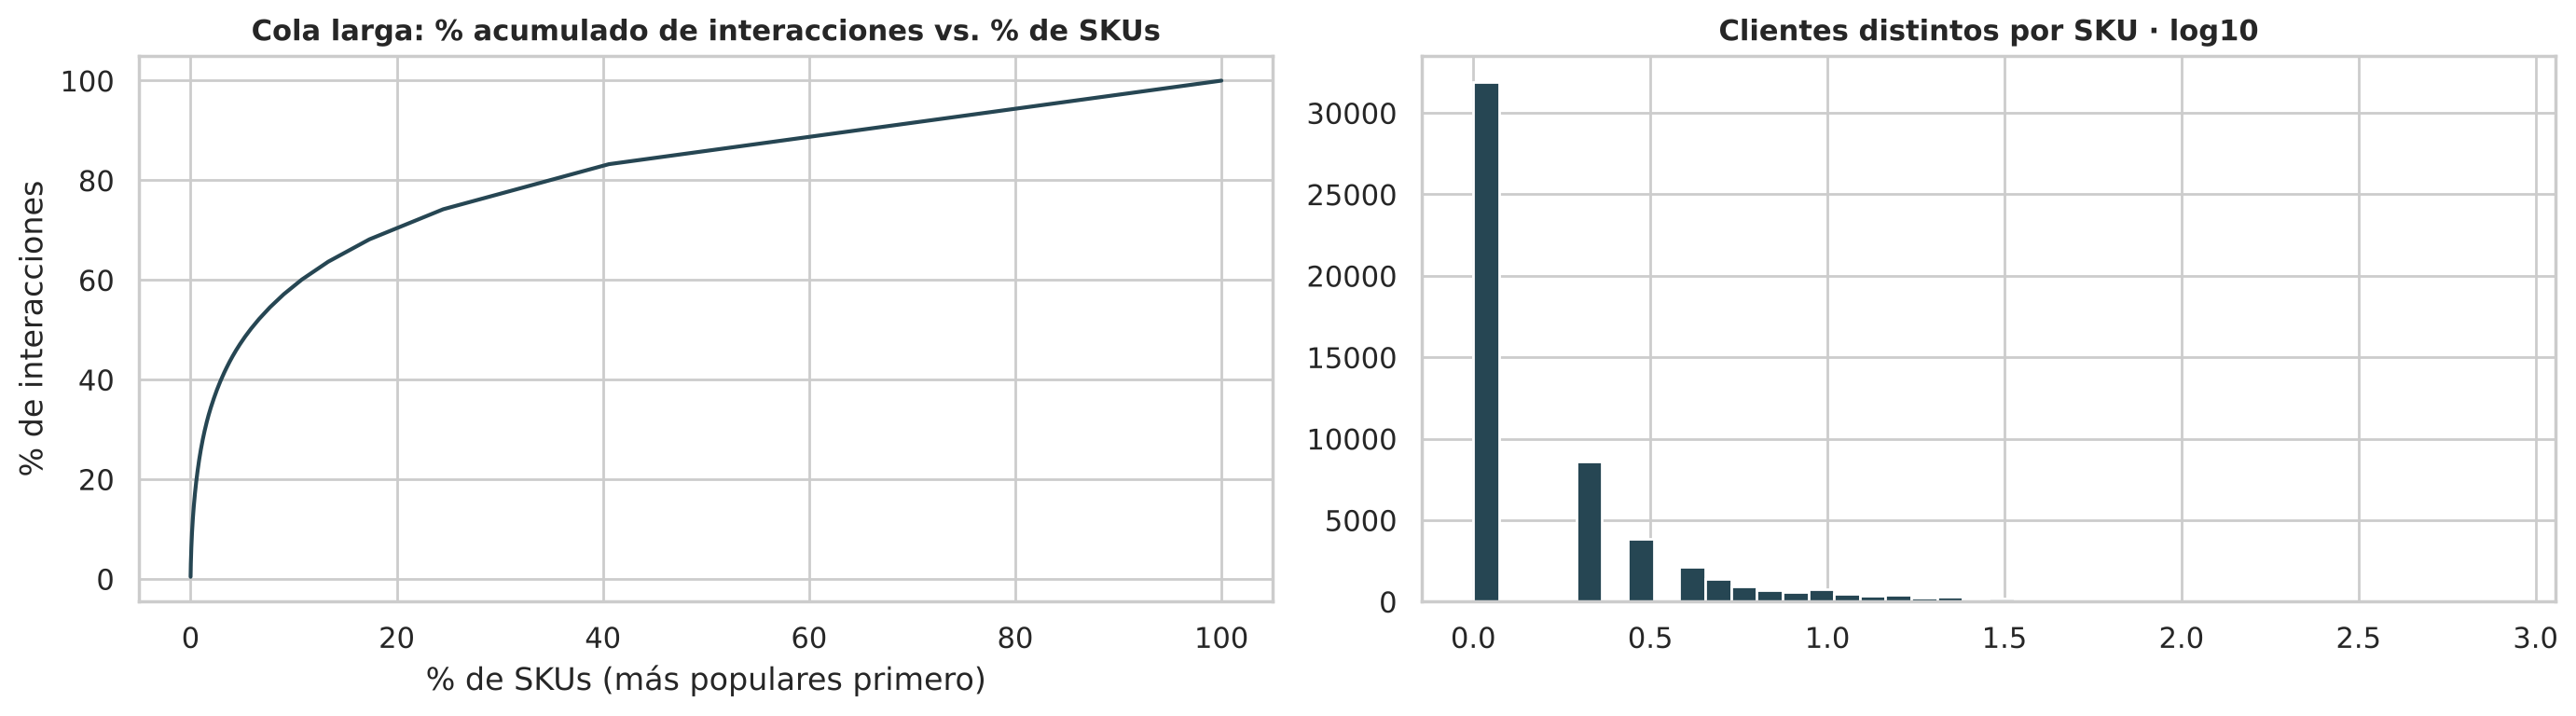

In [ ]:
# 8.4 Dispersión, cola larga y cold-start
n_u, n_i = inter.customer_id.nunique(), inter.sku.nunique()
pop = inter.groupby("sku").size().sort_values(ascending=False)
cum = pop.cumsum() / pop.sum()
n50, n80 = (cum < .5).sum() + 1, (cum < .8).sum() + 1
ndis = inter.groupby("customer_id").size()
print(f"Matriz cliente×SKU: {n_u:,} × {n_i:,} · densidad {len(inter) / (n_u * n_i):.4%} | cliente×categoría: {inter[['customer_id', 'categoria']].drop_duplicates().shape[0] / (n_u * inter.categoria.nunique()):.1%}")
print(f"SKUs para cubrir el 50 % / 80 % de las interacciones: {n50:,} ({n50 / n_i:.1%}) / {n80:,} ({n80 / n_i:.1%})")
print(f"SKUs con >= 5 clientes: {(pop >= 5).mean():.1%} · con 1 solo cliente: {(pop == 1).mean():.1%}")
print(f"Clientes con >= 2 SKUs distintos: {(ndis >= 2).mean():.1%} · >= 5: {(ndis >= 5).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color=AZUL)
ax[0].set(title="Cola larga: % acumulado de interacciones vs. % de SKUs", xlabel="% de SKUs (más populares primero)", ylabel="% de interacciones")
ax[1].hist(np.log10(pop.values), bins=40, color=AZUL); ax[1].set_title("Clientes distintos por SKU · log10")
plt.tight_layout(); plt.show()

**Lectura**
- La matriz cliente×SKU es **extremadamente rala (densidad 0,0045 %)**; a nivel categoría sube al 9,1 %. El 59,5 % de los SKUs tiene un único comprador, y 3.101 SKUs (5,8 %) cubren la mitad de las interacciones (18.671, el 34,8 %, para el 80 %).
- Solo el 44,8 % de los clientes compró 2 o más SKUs distintos y el 12,6 % compró 5 o más: un modelo "quien compró A compró B" tiene señal para menos de la mitad de la base.
- **Propuesta:** modelo en dos niveles, primero categoría (denso) y luego producto dentro de la categoría, rankeado por popularidad reciente, precio y calidad.

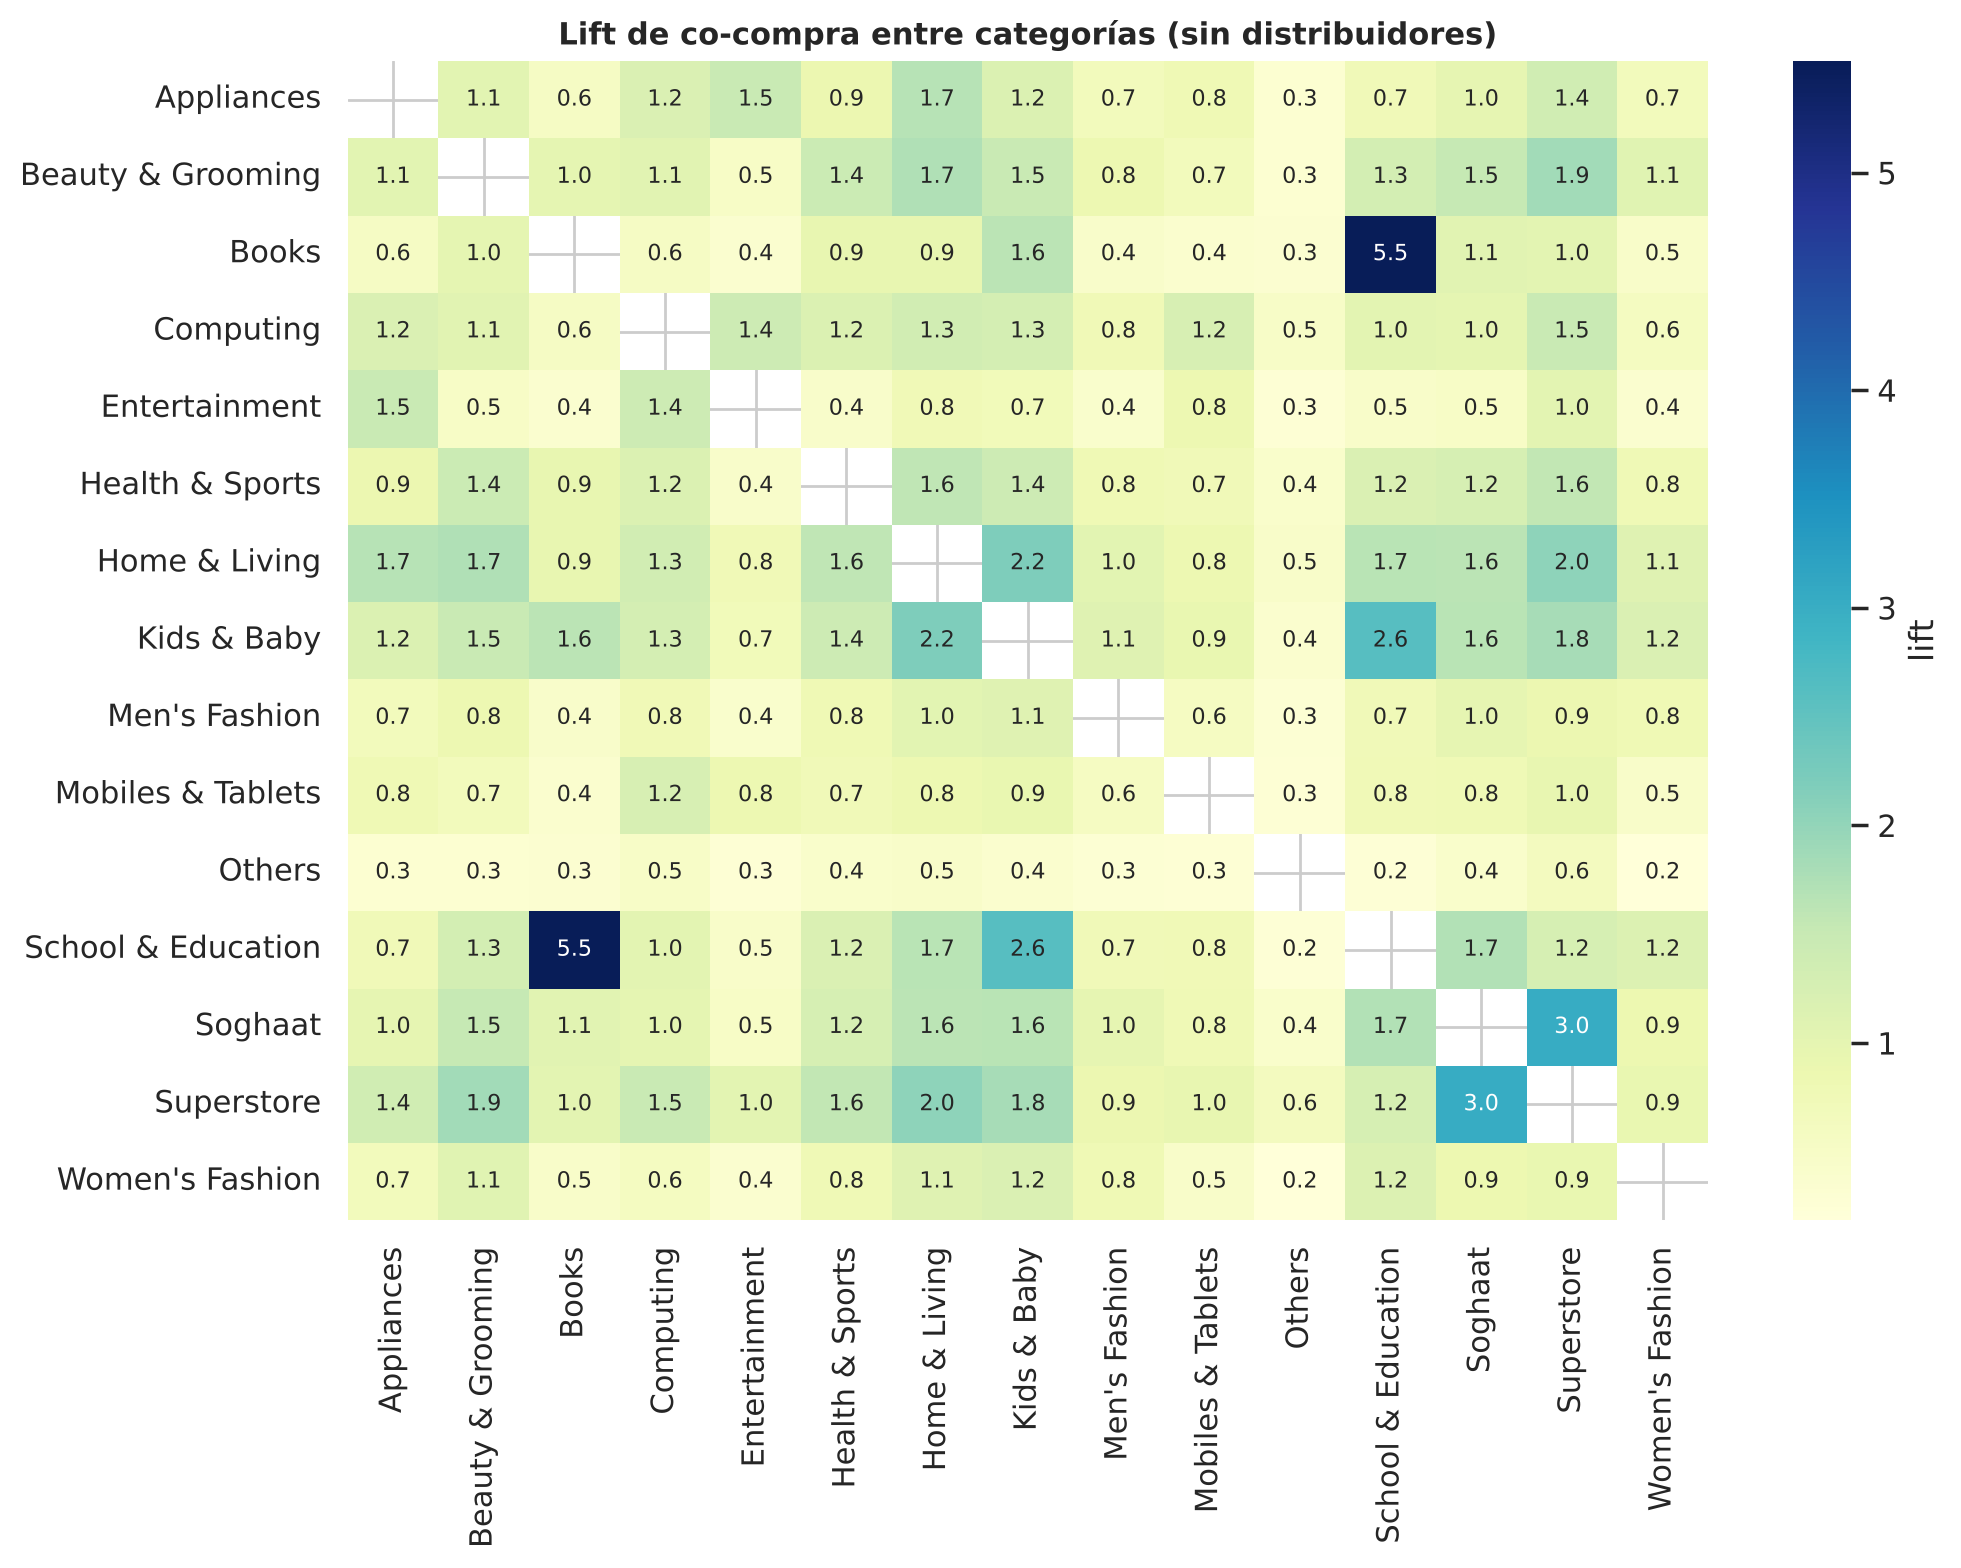

Lift promedio: 1.03 · Others con el resto: promedio 0.36 (rango 0.18–0.63)
                a                  b  lift
            Books School & Education   5.5
          Soghaat         Superstore   3.0
      Kids & Baby School & Education   2.6
    Home & Living        Kids & Baby   2.2
    Home & Living         Superstore   2.0
Beauty & Grooming         Superstore   1.9


In [ ]:
L = lift(v)
plt.figure(figsize=(10.5, 8)); sns.heatmap(L, annot=True, fmt=".1f", cmap="YlGnBu", annot_kws={"size": 8}, cbar_kws={"label": "lift"})
plt.title("Lift de co-compra entre categorías (sin distribuidores)"); plt.xlabel(""); plt.ylabel(""); plt.tight_layout(); plt.show()
par = L.rename_axis(index="a", columns="b").stack().reset_index(name="lift"); par = par[par.a < par.b].nlargest(6, "lift")
print(f"Lift promedio: {np.nanmean(L.values):.2f} · Others con el resto: promedio {L.loc['Others'].mean():.2f} (rango {L.loc['Others'].min():.2f}–{L.loc['Others'].max():.2f})")
print(par.round(1).to_string(index=False))

**Lectura**
- Sin distribuidores las co-compras son **selectivas** (lift promedio 1,03). Las asociaciones fuertes son pocas y con sentido: *Books–School & Education* (5,5), *Soghaat–Superstore* (3,0), *Kids & Baby–School & Education* (2,6), *Home & Living–Kids & Baby* (2,2) y *Home & Living–Superstore* (2,0).
- *Others* está aislada: lift promedio de 0,36 con el resto (rango 0,18-0,63). Quien compra ahí compra solo ahí.

In [ ]:
# Propuesta de split temporal y qué tan "evaluable" es cada partición
F_VAL, F_TEST = pd.Timestamp("2018-07-01"), pd.Timestamp("2018-08-01")
tr, te = v[v.created_at < F_VAL], v[v.created_at >= F_TEST]
u_tr, i_tr, par_tr = set(tr.customer_id), set(tr.sku), set(zip(tr.customer_id, tr.sku))
te_par = te.groupby(["customer_id", "sku"]).size().reset_index()[["customer_id", "sku"]]
te_par["cliente_visto"], te_par["item_visto"] = te_par.customer_id.isin(u_tr), te_par.sku.isin(i_tr)
te_par["recompra"] = [p in par_tr for p in zip(te_par.customer_id, te_par.sku)]
te_par["evaluable"] = te_par.cliente_visto & te_par.item_visto
n_tr = tr.groupby("customer_id").increment_id.nunique()
te_par["perfil_en_train"] = pd.cut(te_par.customer_id.map(n_tr).fillna(0), [-1, 0, 1, 4, np.inf], labels=["Sin historial"] + ORDEN_PERFIL)

print(f"Train: {tr.created_at.min():%Y-%m-%d} → {tr.created_at.max():%Y-%m-%d} ({len(tr):,} líneas)")
print(f"Test:  {te.created_at.min():%Y-%m-%d} → {te.created_at.max():%Y-%m-%d} ({len(te):,} líneas · {len(te_par):,} pares cliente×SKU · {te.customer_id.nunique():,} clientes)")
print(f"Clientes del test vistos en train: {te.customer_id.drop_duplicates().isin(u_tr).mean():.1%} · SKUs vistos: {te.sku.drop_duplicates().isin(i_tr).mean():.1%}")
print(f"Pares con cliente e ítem vistos: {te_par.evaluable.mean():.1%} · pares que ya ocurrieron en train (recompra): {te_par.recompra.mean():.1%}")
g = te_par.groupby("perfil_en_train", observed=True).agg(pares=("sku", "size"), item_visto=("item_visto", "mean"), evaluable=("evaluable", "mean"))
g["% de los pares"] = g.pares / g.pares.sum() * 100; g[["item_visto", "evaluable"]] *= 100
g.round(1)

Train: 2016-07-01 → 2018-06-30 (206,452 líneas)
Test:  2018-08-01 → 2018-08-28 (4,132 líneas · 3,497 pares cliente×SKU · 1,886 clientes)


Clientes del test vistos en train: 39.3% · SKUs vistos: 34.0%
Pares con cliente e ítem vistos: 18.3% · pares que ya ocurrieron en train (recompra): 1.3%


,pares,item_visto,evaluable,% de los pares
perfil_en_train,,,,
Sin historial,2031,39.8,0.0,58.1
Bajo perfil,452,39.4,39.4,12.9
Perfil intermedio,546,42.1,42.1,15.6
Alto perfil,468,49.6,49.6,13.4


**Lectura:** split temporal propuesto: **train hasta 2018-06-30, validación en julio y test en agosto de 2018** (4.132 líneas, 3.497 pares cliente×SKU, 1.886 clientes). Es exigente: solo el 39 % de los clientes del test estaba en train, el 34 % de los SKUs ya existía y apenas el **18,3 %** de los pares es evaluable por filtrado colaborativo. Las recompras son el 1,3 %.

Lo más importante es la composición por perfil: el **58 % de los pares viene de clientes sin historial** y los intermedios aportan solo 546 pares (16 %). Por eso conviene (1) medir **por perfil**, (2) usar **ventanas móviles** para tener más casos de intermedios, (3) incluir baselines de popularidad reciente por categoría (que además es la estrategia para clientes nuevos) y (4) no usar split aleatorio, que filtraría el futuro.

In [ ]:
# Exportación: transacciones sin distribuidores + variables de cliente (se cruzan por customer_id)
tx = df.drop(columns="grupo_status").merge(cf, left_on="customer_id", right_index=True, how="left", suffixes=("", "_cli"))
tx.to_parquet(DIR_SALIDA / "transacciones_sin_distribuidores.parquet", index=False)
items.to_parquet(DIR_SALIDA / "items_features.parquet")
cf.to_parquet(DIR_SALIDA / "clientes_features.parquet")
inter.drop(columns=["es_alto", "es_interm"]).to_parquet(DIR_SALIDA / "interacciones.parquet", index=False)

assert len(tx) == len(df), "el merge cambió la cantidad de filas"
assert inter.groupby(["customer_id", "sku"]).ngroups == len(inter)
assert cf.index.is_unique and items.index.is_unique
assert set(cf.perfil_cliente.unique()) == set(ORDEN_PERFIL) and cf.perfil_cliente.notna().all()
assert (cf.perfil_cliente == "Bajo perfil").eq(cf.n_pedidos == 1).all() and (cf.perfil_cliente == "Alto perfil").eq(cf.n_pedidos >= 5).all()
assert cf.drop(columns="categoria_favorita").select_dtypes("number").notna().all().all(), "NaN en features de cliente"
assert set(cf.index) == set(inter.customer_id) and set(items.index) == set(inter.sku)
assert not cf.index.isin(ids_dist).any() and not tx.customer_id.isin(ids_dist).any(), "quedó un distribuidor en las tablas finales"
for f in ("transacciones_sin_distribuidores", "clientes_features", "items_features", "interacciones", "distribuidores_excluidos"):
    p = DIR_SALIDA / f"{f}.parquet"; print(f"✓ {p.name:<40} {p.stat().st_size / 1e6:5.1f} MB")

✓ transacciones_sin_distribuidores.parquet  23.7 MB
✓ clientes_features.parquet                  2.3 MB
✓ items_features.parquet                     2.0 MB
✓ interacciones.parquet                      3.4 MB
✓ distribuidores_excluidos.parquet           0.1 MB


### Diccionario de variables derivadas

**`clientes_features`** (cliente). Estas 47 columnas también se agregan a `transacciones_sin_distribuidores` cruzando por `customer_id`.

| Variable | Descripción |
|---|---|
| **`perfil_cliente`** | **Bajo perfil** (1 pedido válido), **Perfil intermedio** (2-4) o **Alto perfil** (5+). Categórica ordenada |
| `pedidos_para_alto_perfil` | Pedidos que le faltan para llegar a 5 (0 si ya es alto perfil) |
| `n_pedidos`, `n_lineas`, `unidades`, `gasto_bruto`, `ticket_mediano`, `unidades_por_pedido`, `max_unidades_pedido` | Volumen y valor |
| `skus_distintos`, `n_categorias`, `meses_activos`, `pedidos_por_mes_activo`, `nivel_historial_skus` | Variedad y actividad; `nivel_historial_skus` = frío (1 SKU), tibio (2-4) o cálido (5+) |
| `recencia_dias`, `R`, `F`, `M`, `rfm_score` | RFM con quintiles de 1 (peor) a 5 (mejor) |
| `antiguedad_dias`, `dias_alta_a_primera_compra` | Antigüedad y rapidez de activación |
| `categoria_favorita`, `concentracion_categoria_fav`, `entropia_categorias`, `share_cat_*` (16) | Perfil de categorías |
| `pct_cod`, `pct_codigo_comision`, `tasa_cancelacion`, `tasa_reembolso` | Canal, pago y fricción |
| `zona_gris`, `n_senales_dist`, `cuenta_interna` | Zona gris, señales de distribuidor (0-2) y cuenta probablemente de la tienda (excluir de rankings) |

**`items_features`** (SKU)

| Variable | Descripción |
|---|---|
| `n_clientes`, `popularidad_log`, `rank_popularidad` | Popularidad por clientes distintos |
| `precio_mediano`, `pct_precio_en_categoria`, `nivel_precio` | Precio y posición relativa en su categoría (económico, medio, premium) |
| `tasa_recompra` | Proporción de compradores que repiten |
| `pct_compradores_alto_perfil`, `pct_compradores_intermedios` | Parte de sus compradores en cada perfil |
| `dias_desde_ultima_venta`, `vida_dias`, `activo_90d`, `item_frio` | Vigencia y cold start (frío = menos de 5 compradores) |
| `tasa_cancelacion_suav`, `tasa_reembolso_suav` | Calidad percibida, con suavizado bayesiano |

**`interacciones`** (cliente × SKU)

| Variable | Descripción |
|---|---|
| `n_compras`, `unidades`, `monto_bruto` | Pedidos distintos, unidades y monto bruto del par |
| `feedback_implicito`, `recompra` | `log1p(unidades)` y marca de compra en más de un pedido |
| `dias_desde_ultima`, `peso_temporal` | Recencia y peso `exp(−días/90)` |
| `categoria`, `perfil_cliente` | Categoría del SKU y perfil del cliente |

## 9. Conclusiones y próximos pasos

**Hallazgos clave**
1. **Datos coherentes:** el parquet cumple las validaciones del ETL. Solo el 50,6 % de las transacciones son compras válidas, y esa es la base correcta para el recomendador.
2. **Distribuidores excluidos:** 1.824 clientes (2,3 %) concentraban el 32 % de las líneas válidas y el 22,7 % del gasto. Se definen por frecuencia, variedad y volumen, **no por ticket**, y sacarlos baja el lift de co-compra de 1,59 a 1,03. La zona gris (1.323) se mantiene, marcada con `zona_gris`.
3. **Base limpia:** 78.122 clientes y 147.333 pedidos válidos. El 66,1 % compró una sola vez y el 44 % compró un único producto en una sola unidad.
4. **Perfiles:** 66,1 % bajo perfil, 27,2 % intermedio y 6,7 % alto. **El intermedio genera el 39,5 % del gasto.** El alto perfil gasta 4,3 veces más con el mismo ticket: la diferencia es la **frecuencia**.
5. **La conversión natural es baja y depende de la recencia:** solo el 3,9 % de los intermedios llegó a alto perfil en ~6 meses; sube al 11 % con 4 pedidos y al 15,2 % si compraron en los últimos 30 días, y cae al 1,3 % si llevan más de 180 días sin comprar.
6. **El catálogo es efímero:** el 59,9 % de los SKUs se vende en un solo día, el 86,7 % tiene menos de 5 compradores y solo el 12,6 % está activo. La densidad cliente×SKU es 0,0045 %.
7. **Hay estacionalidad por categoría y cambio en los medios de pago**, y el método de pago explica gran parte de la cancelación.

**Decisiones para el modelado**
- Entrenar con `transacciones_sin_distribuidores`. **Target:** clientes de perfil intermedio. **Métrica de negocio:** conversión a alto perfil frente a la línea de base de 3,9 %.
- Priorizar a los intermedios **activos** y a los de 3-4 pedidos; para los dormidos, una acción de reactivación distinta.
- Modelo en dos niveles, **categoría → producto**, con popularidad reciente, precio relativo y calidad; filtrado colaborativo solo para clientes cálidos. Recomendar solo ítems **activos** y usar `peso_temporal`.
- Los clientes de bajo perfil no son objetivo, pero aportan señal de popularidad y co-compra. Los clientes nuevos (58 % de los pares del test) se atienden con un baseline de popularidad por categoría.
- Evaluar por perfil y con **ventanas móviles**; excluir `cuenta_interna` de rankings y de la evaluación.

**Riesgos y pendientes**
- La detección de distribuidores es una **regla con umbrales** (percentil 97 y 50 unidades): conviene validar una muestra con el negocio. La zona gris se parece a los distribuidores en canal y pago, así que hay que probar el modelo con y sin ella; dentro de ella quedan clientes de gasto muy alto y poca variedad (44619, 109038, 110215).
- Los perfiles son un **continuo**: los cortes 1 / 2-4 / 5+ son una decisión de negocio.
- La conversión histórica de 3,9 % tiene efecto cohorte: sirve de referencia, no como efecto causal.
- `Desconocida` (88 % en 2016) es deuda de calidad de datos, y sin atributos de producto (nombre, marca, descripción) el `sku` es un código opaco: conseguirlos mejoraría el manejo de ítems fríos.

**Archivos generados** (en la carpeta de salida): `transacciones_sin_distribuidores.parquet` (23 columnas originales + 47 variables de cliente), `clientes_features`, `items_features`, `interacciones` y `distribuidores_excluidos`. Próximo notebook: `03_modelado`.